# Committor from an infretis StapleTIS Run (2D)

Fits the committor with NPNEq (`CommittorNE`, CuPy) to the paths of an **infretis StapleTIS** simulation of a 2D system (order parameter y and a second coordinate x in `order.txt`) and compares it with the exact committor, along y and on the (y, x) plane.

**How the paths become training data** (the same code as `load_tis_data_cupy.py`: `tis_data.prepare_data`, which switches to `infretis_data.py` for infretis runs; details in `docs/npneq_tis_notes.md`, sections 3, 9 and 15):
- **Read with infretis' own definitions:** interfaces and swap settings from `infretis.toml`, one row per finished path from `infretis_data.txt`, the order parameters (all columns of `order.txt`: y, x, ...) from `load/<pnr>/order.txt` (or an h5 archive), and each path's core in an ensemble from infretis' `StaplePath.get_sh_region`.
- **Cut at M:** an ensemble only keeps paths that cross its middle interface M, so the frames before that crossing are conditioned on their future. Every (path, ensemble) pair gives one piece: the path from its first frame past M (searched from the core start) to its end. Optionally also the *mirrored piece*: the part before the last M crossing, read backwards (`REVERSED`).
- **Weights:** infretis records per (path, ensemble) the occupancy `path_f` and the weight `path_w` it put into the swap matrix (0.5 for LML/RMR paths in the inner staple ensembles). The weighting has to undo how the sampler used w: with swaps (infinite swap or staple swaps) that is `path_f / path_w` (`'staple'`), with shooting only `path_f` (`'rejections'`). By default the loader picks this from the run (`WEIGHTINGS = [None]`); several weightings can be fitted side by side by listing them.

**Default run: a format copy, not an infretis simulation.** There is no infretis StapleTIS run of a 2D toy system yet. `sim_istarz_br_g10_infretis` holds 500 paths per ensemble of the toytis staple run `sim_istarz_br_g10` (2D Brownian Z potential, γ = 10, kT = 0.05, dt = 0.002; interfaces 0.05, 0.13, …, 0.85) written in the infretis layout by `figures_by_potential/2d_zpot/brownian_g10/staple/infretis_copy/convert_toytis_to_infretis.py`. The infretis reader makes from it exactly the pieces the toytis reader makes (4990 of 4990 identical; `--check`). Its `infretis.toml` declares shooting only, as the toytis sampler did, so the default weighting is `path_f`. Point `TIS_DIR` at a real infretis run when there is one.

**Exact committor:** the discrete-time solution on a grid for the Z potential (`figures_by_potential/2d_zpot/exact/q_exact_staple_h0.001.npz`, A: y ≤ 0.05, B: y ≥ 0.85, absorption checked every step; notes §13.3), with the potential's contours for the maps. For another run, set `q_exact_of = None` or give its exact committor (section 5).

## 1. Imports

In [1]:
import argparse
import os
import sys
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cupy as cp

plt.rc('font', size=10)
plt.rc('axes', titlesize=12)
plt.rc('axes', labelsize=12)
plt.rc('legend', fontsize=9)

# Run from examples/: the CuPy optimalrcs package and the path readers of the examples
REPO = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
sys.path.insert(0, f'{REPO}/optimalrcs-cupy/')
sys.path.insert(0, f'{REPO}/examples/')
import optimalrcs
import tis_data
import infretis_data
import seed_runs
FIG = f'{REPO}/examples/figures_by_potential'

## 2. Settings

**Run and data**

| Name | Meaning |
|---|---|
| `TIS_DIR` | the infretis simulation folder (`infretis.toml`, `infretis_data.txt`, `load/`) |
| `H5_FILE` | order parameters from an `inft store_txt -order` archive instead of `load/` (`None`: use `load/`) |
| `LAMBDA_A`, `LAMBDA_B` | states A (λ ≤ λ_A) and B (λ ≥ λ_B); `None`: the first and last interface |
| `BURN_IN_FRACTION` | the first part of the rows of `infretis_data.txt` (the order in which the paths ended) is skipped; the initial load paths always are |
| `PATHS_PER_ENSEMBLE`, `THIN` | at most this many paths per ensemble, evenly spaced (`None`: all), after keeping every `THIN`-th |
| `REVERSED` | also use the mirrored pieces (time-reversible dynamics at equilibrium) |
| `WEIGHTINGS` | the weightings to fit, one fit each: `None` = the run's default, `'staple'` = path_f / path_w, `'rejections'` = path_f, `'none'` = 1 per (path, ensemble). One entry is enough; list several to compare them |

**Fit** (the same for every weighting): `SEEDS` (which CV and envelope centre each iteration draws), a warm-up of `WARMUP_ITER` iterations with a wide envelope, then `MAX_ITER` iterations, in chunks of `CHUNK` after which the plots are shown and saved. `STOPPED_ENDS` (default `True`): a piece that ends outside A and B was stopped by the path's own end (a turn); the stopped Z_q then uses q at that end for windows that pass it (`set_stopped_traj_end`), and the A/B traps are made long enough that no window is dropped. `NY` is the degree of the polynomial basis, `LAZY_BASIS` evaluates it on the fly (GPU memory).

In [3]:
TIS_DIR = f'{REPO}/examples/data/infretis_inputs/cc_br'
H5_FILE = f'{REPO}/examples/data/infretis_inputs/cc_br/paths.h5'
LAMBDA_A, LAMBDA_B = 0.15, 0.85    # None: first and last interface
BURN_IN_FRACTION = 0.3
PATHS_PER_ENSEMBLE = 5000          # None: all paths after the burn-in
THIN = 1
REVERSED = True
WEIGHTINGS = ['rejections']                # e.g. [None], ['staple', 'rejections']
N_CVS = None                       # train on the first N CVs of order.txt (None: all)

SEEDS = [1]
WARMUP_ITER, WARMUP_ENVELOPE = 1000, 1
MAX_ITER, CHUNK = 10000, 2500
ENVELOPE, GAMMA = 0.01, 0.1
STOPPED_ENDS = True                # stopped Z_q: a window passing a turn end of a piece uses q at that end
NY, LAZY_BASIS = 6, True           # basis degree; evaluate the basis on the fly (GPU memory)
PLOTS = ('metrics', 'tis', 'feps', 'obs_pred', 'obs_pred_log')         # library plots after every chunk; also possible: 'feps', 'obs_pred', 'obs_pred_log'
LABELS = ('order parameter $y$', '$x$')
#EDGES = (np.linspace(0.15, 0.85, 81), np.linspace(-0.01, 0.31, 33))   # (lambda, CV 1) bins; None: from the data
EDGES = (np.linspace(0.15, 0.85, 81), np.linspace(-0.4, 0.5, 46))

RUN_NAME = os.path.basename(TIS_DIR.rstrip('/'))
OUT = f'{FIG}/2d_curved_channel/brownian_g10/staple/infretis_copy/{RUN_NAME}'
print('figures and results in', OUT)

figures and results in /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/2d_curved_channel/brownian_g10/staple/infretis_copy/cc_br


## 3. The Run

What infretis wrote: the sampling settings, and per ensemble its window (L, M, R), the number of finished paths with a nonzero occupancy, their total occupancy `path_f`, and the share of that occupancy with `path_w` ≠ 1 (where `'staple'` and `'rejections'` differ).

**Weight check** (`infretis_data.weight_consistency`, needs no committor). A path that is valid in two ensembles e and e′ should split its occupancy in the same ratio C_e / C_e′ whatever its type. So the ratio Σ weight_e / Σ weight_e′ over paths of one class (w_e, w_e′) must not depend on the class: relative to class (1, 1), the classes (0.5, 1) and (1, 0.5) should give 1 for the right weighting. Runs with swaps show which one that is. Runs with shooting only have no paths shared between ensembles, and the check is empty.

In [4]:
settings = infretis_data.read_settings(TIS_DIR)
table = infretis_data.read_infretis_data(os.path.join(TIS_DIR, 'infretis_data.txt'), len(settings['interfaces']))
default_w, why = infretis_data.default_weighting(settings)
print(f"mode {settings['mode']}, infinite swap {settings['infinite_swap']}, staple swap fraction "
      f"{settings['staple_swap_frac']}, {len(table['pnr'])} finished paths")
print(f"interfaces {settings['interfaces']}")
print(f"default weighting: {default_w} ({why})")

f, w = table['path_f'], table['path_w']
rows = []
for e in range(len(settings['interfaces'])):
    on = f[:, e] > 0
    rows.append(dict(ensemble=f'{e:03d}', window=tuple(round(v, 4) for v in infretis_data.ensemble_window(settings, e)),
                     paths=int(on.sum()), occupancy=f[on, e].sum(),
                     share_w_not_1=(f[on, e] * ~np.isclose(w[on, e], 1)).sum() / max(f[on, e].sum(), 1e-12)))
display(pd.DataFrame(rows).set_index('ensemble').round(3))

check = infretis_data.weight_consistency(table)
if not check:
    print('weight check: no pairs of ensembles with enough shared paths (expected for shooting only)')
else:
    out = []
    for row in check:
        for c in ((0.5, 1), (1, 0.5)):
            if c in row:
                out.append(dict(pair=row['pair'], cls=c, n=row['n'][c],
                                path_f=f"{row[c]['rejections'][0]:.3f} ± {row[c]['rejections'][1]:.3f}",
                                path_f_over_w=f"{row[c]['staple'][0]:.3f} ± {row[c]['staple'][1]:.3f}"))
    display(pd.DataFrame(out))

mode staple, infinite swap True, staple swap fraction 0.5, 60848 finished paths
interfaces [0.15, 0.22, 0.29, 0.36, 0.43, 0.5, 0.57, 0.64, 0.71, 0.78, 0.85]
default weighting: staple (StapleTIS with infinite swap: the permanent of W splits the occupancies by w)


,window,paths,occupancy,share_w_not_1
ensemble,,,,
000,"(-inf, 0.15, 0.15)",9799,72822.000,0.000
001,"(0.15, 0.15, 0.22)",11168,73618.234,0.000
002,"(0.15, 0.22, 0.29)",9528,74176.234,0.102
003,"(0.22, 0.29, 0.36)",10968,71727.341,0.623
004,"(0.29, 0.36, 0.43)",10971,69715.077,0.600
005,"(0.36, 0.43, 0.5)",11087,67586.115,0.511
006,"(0.43, 0.5, 0.57)",11193,67455.545,0.476
007,"(0.5, 0.57, 0.64)",11342,67825.553,0.510
008,"(0.57, 0.64, 0.71)",11673,70263.450,0.562


,pair,cls,n,path_f,path_f_over_w
0,"(2, 3)","(0.5, 1)",1017,0.464 ± 0.021,0.928 ± 0.043
1,"(2, 3)","(1, 0.5)",1811,1.861 ± 0.124,0.930 ± 0.062
2,"(2, 4)","(0.5, 1)",504,0.446 ± 0.050,0.893 ± 0.099
3,"(2, 4)","(1, 0.5)",792,1.600 ± 0.158,0.800 ± 0.079
4,"(2, 5)","(0.5, 1)",268,0.468 ± 0.130,0.936 ± 0.261
...,...,...,...,...,...
59,"(8, 9)","(1, 0.5)",685,1.980 ± 0.101,0.990 ± 0.050
60,"(8, 10)","(0.5, 1)",1126,0.557 ± 0.048,1.113 ± 0.096
61,"(8, 10)","(1, 0.5)",415,2.235 ± 0.157,1.118 ± 0.078
62,"(9, 10)","(0.5, 1)",1897,0.557 ± 0.042,1.114 ± 0.084


## 4. From Paths to Frames

`tis_data.prepare_data` reads the run once per weighting in `WEIGHTINGS` (the pieces are the same, only their weights differ). It returns per frame: the CVs, λ, the time within its path (`t_traj`), its piece (`i_traj`), its path (`group_traj`, the infretis path number), the path weight (`path_weights`, mean 1) and the A/B masks.

The plots show where the frames are: the weighted number of frames along λ (the path-sampling density, high at the interfaces where pieces start, not the equilibrium distribution), and the piece lengths.

State A: order <= 0.15, state B: order >= 0.85
infretis run /local/data/data-fbsskr/Students/elias/optimalrcs/examples/data/infretis_inputs/cc_br: mode staple, infinite swap True, 11 ensembles, 60848 finished paths in /local/data/data-fbsskr/Students/elias/optimalrcs/examples/data/infretis_inputs/cc_br/infretis_data.txt
Interfaces: [0.15, 0.22, 0.29, 0.36, 0.43, 0.5, 0.57, 0.64, 0.71, 0.78, 0.85]
  path_w != 1 for 42868 (path, ensemble) pairs, 36.2% of the occupancy; path_f and path_f / path_w differ there by a factor [2.]
  Note (StapleTIS): path_f / path_w is the natural measure of the stored staple paths (crossing probabilities, rates). For committor pieces use path_f (--weights rejections): an LML/RMR core is stored twice, once with each turn (the extension's coin flip, w = 1/2 each), and path_f counts the core once; see docs/op_loop_report.md.
Order parameters from /local/data/data-fbsskr/Students/elias/optimalrcs/examples/data/infretis_inputs/cc_br/paths.h5: 29368 paths read
  en

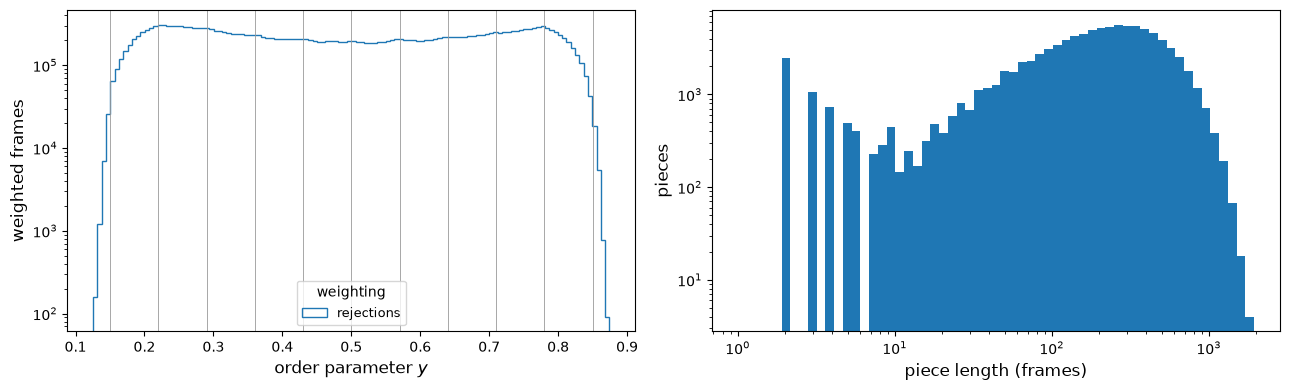

In [5]:
def prepare(weighting):
    parser = argparse.ArgumentParser()
    tis_data.add_data_arguments(parser)
    argv = [TIS_DIR, '--burn-in-fraction', str(BURN_IN_FRACTION), '--thin', str(THIN)]
    if weighting is not None:
        argv += ['--weights', weighting]
    if H5_FILE is not None:
        argv += ['--h5', H5_FILE]
    if LAMBDA_A is not None:
        argv += ['--lambda-a', str(LAMBDA_A)]
    if LAMBDA_B is not None:
        argv += ['--lambda-b', str(LAMBDA_B)]
    if PATHS_PER_ENSEMBLE is not None:
        argv += ['--paths-per-ensemble', str(PATHS_PER_ENSEMBLE)]
    if REVERSED:
        argv += ['--reversed']
    if N_CVS is not None:
        argv += ['--n-cvs', str(N_CVS)]
    args = parser.parse_args(argv)
    data = tis_data.prepare_data(args)
    if data.X_all.shape[1] == 3:        # SeedLambda writes lambda and then the CVs y, x
        data.X_all = data.X_all[:, 1:]   # -> (y, x), as in the toytis format copy
        data.X = data.X_all if N_CVS is None else data.X_all[:, :N_CVS]
    return args.weights, args.lambda_a, args.lambda_b, data     # the weighting actually used


# None = the run's default (section 3); the same weighting twice is fitted once
names = list(dict.fromkeys(w if w is not None else default_w for w in WEIGHTINGS))
datas = {}
for weighting in names:
    name, lambda_a, lambda_b, data = prepare(weighting)
    datas[name] = data
    print(f'--> {name}: {len(data.lam)} frames, {data.i_traj.max() + 1} pieces, '
          f'{len(np.unique(data.group_traj))} paths\n')
data = next(iter(datas.values()))  # the frames are the same for every weighting
free = ~(data.boundary0 | data.boundary1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))
e_lam = np.linspace(data.lam.min(), data.lam.max(), 121)
for name, d in datas.items():
    ax1.hist(d.lam, bins=e_lam, weights=d.path_weights, histtype='step', label=name)
for v in settings['interfaces']:
    ax1.axvline(v, color='0.6', lw=0.6)
ax1.set(xlabel=LABELS[0], ylabel='weighted frames', yscale='log')
ax1.legend(title='weighting')
lengths = np.bincount(data.i_traj)
ax2.hist(lengths, bins=np.logspace(0, np.log10(lengths.max() + 1), 60))
ax2.set(xscale='log', yscale='log', xlabel='piece length (frames)', ylabel='pieces')
fig.tight_layout()
plt.show()

## 5. Exact Committor

The discrete-time committor of the Z potential's Brownian dynamics, solved on a grid (`exact_tools.eval_q_brownian_2d`, the function the λ fits use), evaluated at every frame's (y, x). It is made for A: y ≤ 0.05, B: y ≥ 0.85 and the time step of the run, so it applies only to this system. For another run, give `q_exact_of(X)` (CVs per frame → q) or set it to `None`. `CONTOURS` (grey lines in the maps) are the effective potential of the Z potential, from the older reference grid.

In [6]:
sys.path.insert(0, f'{FIG}/_shared/exact_committors')
import exact_tools, lgv2d_tools
EXACT = dict(np.load(f'{FIG}/2d_curved_channel/exact/q_exact_h0.0015.npz'))
assert np.isclose(float(EXACT['A']), lambda_a) and np.isclose(float(EXACT['B']), lambda_b), \
    'the exact committor was solved for other states A and B'


def q_exact_of(X):                      # X: (y, x) columns, see fix 1
    q = np.empty(len(X))
    for s in range(0, len(X), 2_000_000):
        q[s:s + 2_000_000] = exact_tools.eval_q_brownian_2d(lgv2d_tools.cc_force, EXACT,
                                                           X[s:s + 2_000_000, 0], X[s:s + 2_000_000, 1])
    q = np.clip(q, 0, 1)
    q[X[:, 0] <= lambda_a], q[X[:, 0] >= lambda_b] = 0, 1
    return q


_y = np.linspace(lambda_a, lambda_b, 281)
_x = np.linspace(-0.45, 0.6, 421)
_Y, _X = np.meshgrid(_y, _x, indexing='ij')                        # V has shape (len(y), len(x)); the plots use V.T
_V = lgv2d_tools.cc_potential(_Y, _X) / float(EXACT['kT'])         # in kT (kT = 0.05)
CONTOURS = (_y, _x, _V, np.arange(0, 12.5, 1.0))

## 6. Fit the Committor

One fit per weighting (and per seed in `SEEDS`), on the same frames. `CommittorNE` with `group_traj` (the pieces of one path count as one unit in the error estimates), the **A/B ends as traps** (`set_fixed_traj_length_trap`: longer than any piece plus the longest Z_q lag, so no window is dropped), and the **stopped ends** (`set_stopped_traj_end`, `STOPPED_ENDS`): a piece that ends outside A and B was stopped by the path's own end (a turn), so a window that passes it uses q at that end instead of being dropped, which would condition on the path not stopping earlier.

The first cell defines the plots, the progress line and the piece ends; the second builds the committor, runs `fit_transform` for the warm-up (wide envelope) and then in chunks of `CHUNK` iterations (it continues from the current q), and `seed_runs.save_and_show` shows and saves after the warm-up and every chunk as `<OUT>/<weighting>/seed<s>/it<N>_<plot>.png`:
- `metrics`: `dr2`, `zqs_z` and `|dx|` over the iterations. **Convergence: `zqs_z`** (the worst |stopped Z_q / standard error| over q and lags) about 2 or less, with `|dx|` small. For pieces cut at M the stopped Z_q of the committor is 0 at every q and lag (notes §5, §8.1);
- `tis`: the stopped Z_q per lag, the short-lag Z_q and the stopped observed-vs-predicted;
- `feps`, `obs_pred` (if listed in `PLOTS`): the library's original plots, biased for path pieces; with `STOPPED_ENDS` the Z_q of `feps` is the stopped one;
- `q_profile`: the path-weighted mean q per λ bin next to the exact committor, and fit − exact;
- `q_map`: the mean q per (y, x) bin, the exact committor and fit − exact, on the potential;

The progress line gives the path-weighted RMS(fit − exact) over the frames with 0.05 < q_exact < 0.95. Each weighting's final q per frame is kept in `fits` for section 7.

In [7]:
def edges_for(d):
    if EDGES is not None:
        return EDGES
    X = d.X_all[~(d.boundary0 | d.boundary1)]
    return tuple(np.linspace(*np.percentile(X[:, k], [0.5, 99.5]), 81 if k == 0 else 33) for k in range(2))


def extras_for(d, qe):
    # q -> figure: the path-weighted mean q per lambda bin, against the exact committor (and the (y, x) map)
    edges = edges_for(d)
    fr = ~(d.boundary0 | d.boundary1)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    mid = (edges[0][1:] + edges[0][:-1]) / 2
    prof_ex = None if qe is None else bm(d.path_weights * qe) / w_mean

    def q_profile(q):
        P = bm(d.path_weights * cp.asnumpy(q.r_traj)) / w_mean
        fig, axes = plt.subplots(1, 1 if qe is None else 2, figsize=(6 if qe is None else 13, 4), squeeze=False)
        axes[0, 0].plot(mid, P, label='fit')
        if qe is not None:
            axes[0, 0].plot(mid, prof_ex, 'k--', label='exact')
            t = (prof_ex > 0.05) & (prof_ex < 0.95)
            axes[0, 1].plot(mid, P - prof_ex)
            axes[0, 1].axhline(0, color='k', lw=0.8)
            axes[0, 1].set(xlabel=XLABEL, ylabel='fit $-$ exact',
                           title=f'RMS per bin (0.05 < exact < 0.95) {np.sqrt(np.nanmean((P - prof_ex)[t] ** 2)):.4f}')
            axes[0, 1].grid(alpha=0.3)
        axes[0, 0].set(xlabel=XLABEL, ylabel='$q$ (mean per bin)')
        axes[0, 0].legend()
        axes[0, 0].grid(alpha=0.3)
        fig.tight_layout()
        return fig

    extras = {'q_profile': q_profile}
    if d.X_all.shape[1] > 1:
        extras['q_map'] = seed_runs.committor_map(
            [seed_runs.plane(d.X_all[:, 0], edges[0], LABELS[0], d.X_all[:, 1], edges[1], LABELS[1],
                             contours=CONTOURS)], mask=fr, q_ref=qe)
    return extras


def report_for(d, qe):
    # progress line: path-weighted RMS(fit - exact) over the frames with 0.05 < q_exact < 0.95
    if qe is None:
        return None
    trans = ~(d.boundary0 | d.boundary1) & (qe > 0.05) & (qe < 0.95)
    idx, qe_g, w_g = (cp.asarray(a) for a in (np.flatnonzero(trans), qe[trans], d.path_weights[trans]))

    def report(q):
        diff = q.r_traj[idx] - qe_g
        return f'| RMS(fit - exact) {float(cp.sqrt(cp.sum(w_g * diff * diff) / cp.sum(w_g))):.4f}'
    return report


XLABEL = LABELS[0]

# ---- piece ends: in A or B (trap), or stopped by the path's own end, a turn (stopped end)
# (the frames are the same for every weighting, so this is done once)
b_all = data.boundary0 | data.boundary1
piece_end = np.r_[np.flatnonzero(np.diff(data.i_traj)), len(data.i_traj) - 1]      # last frame of every piece
stop_end = np.zeros(len(b_all), bool)
stop_end[piece_end] = ~b_all[piece_end]
longest = int(np.bincount(data.i_traj - data.i_traj.min()).max())
TRAP_LEN = max(2 ** 16, longest + 2 ** 15 + 1)         # A/B trap: longer than any piece plus the longest Z_q lag (2^15)
print(f'{len(piece_end)} pieces: {stop_end.sum()} end at a turn (stopped), {len(piece_end) - stop_end.sum()} in A or B; '
      f'longest piece {longest} frames, A/B trap {TRAP_LEN}')

PRINT_STEP = min(500, CHUNK, WARMUP_ITER or CHUNK)    # the metrics are recorded every PRINT_STEP iterations (a plot needs a record)
METRICS = ['delta_r2', 'max_z_zq_stopped', 'delta_x']


def show_stage(q, folder, n_done, stage, extras, report):
    """Save and show the plots after a stage (<folder>/it<N>_<plot>.png), and print the progress."""
    seed_runs.save_and_show(q, folder, f'it{n_done}', PLOTS, dict(metrics=METRICS), extras)
    print(f'{n_done} iterations ({stage}) {"" if report is None else report(q)}', flush=True)


99072 pieces: 62320 end at a turn (stopped), 36752 in A or B; longest piece 1940 frames, A/B trap 65536


===== fit, weighting rejections, seed 1 =====
#=500, dr2=3896.56, zqs_z=1.96641, sdzqs=29.3982, |dx|=0.385487, time=45.4781
#=1000, dr2=3895.07, zqs_z=1.71583, sdzqs=23.5379, |dx|=0.000625282, time=91.0866


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)
/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/2d_curved_channel/brownian_g10/staple/infretis_copy/cc_br/rejections/seed1/it1000 ---


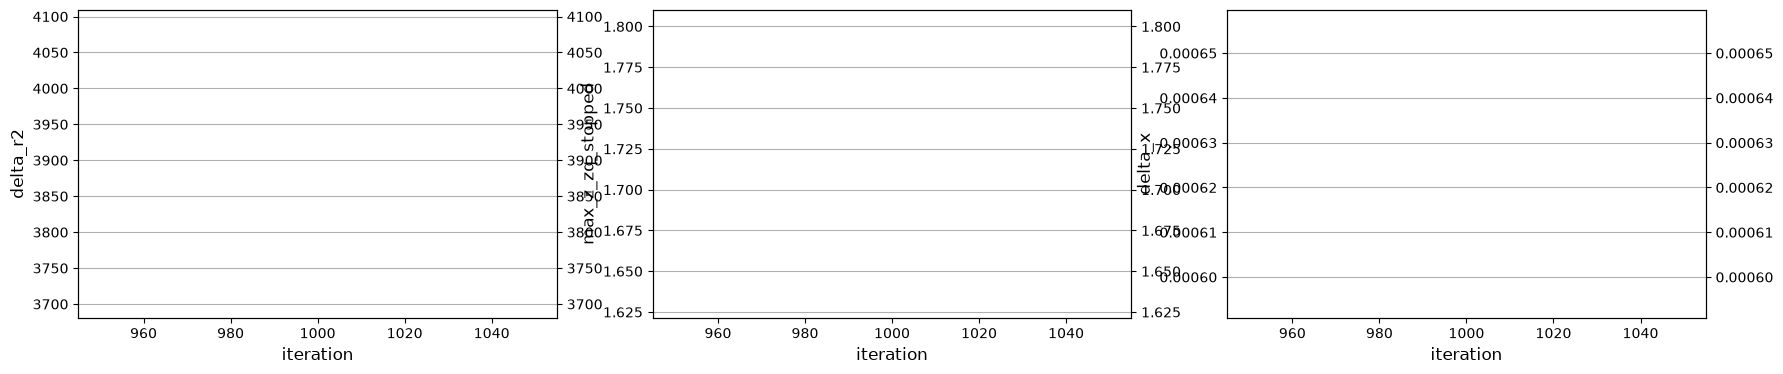

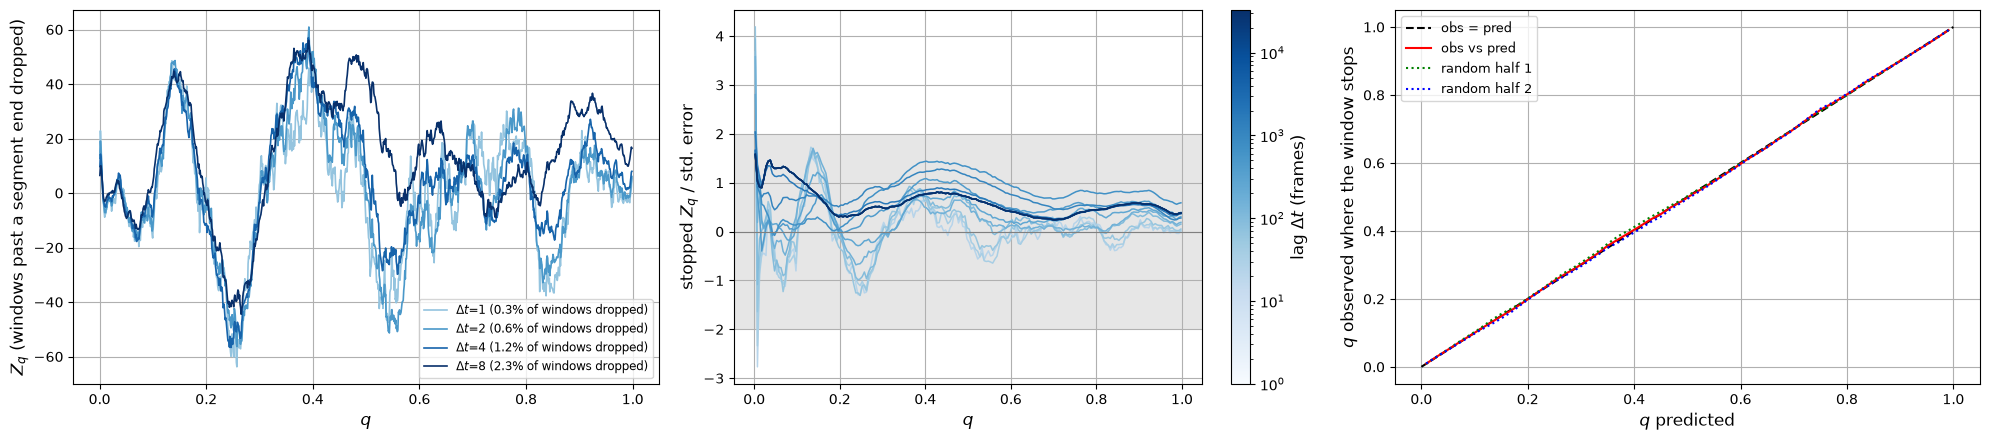

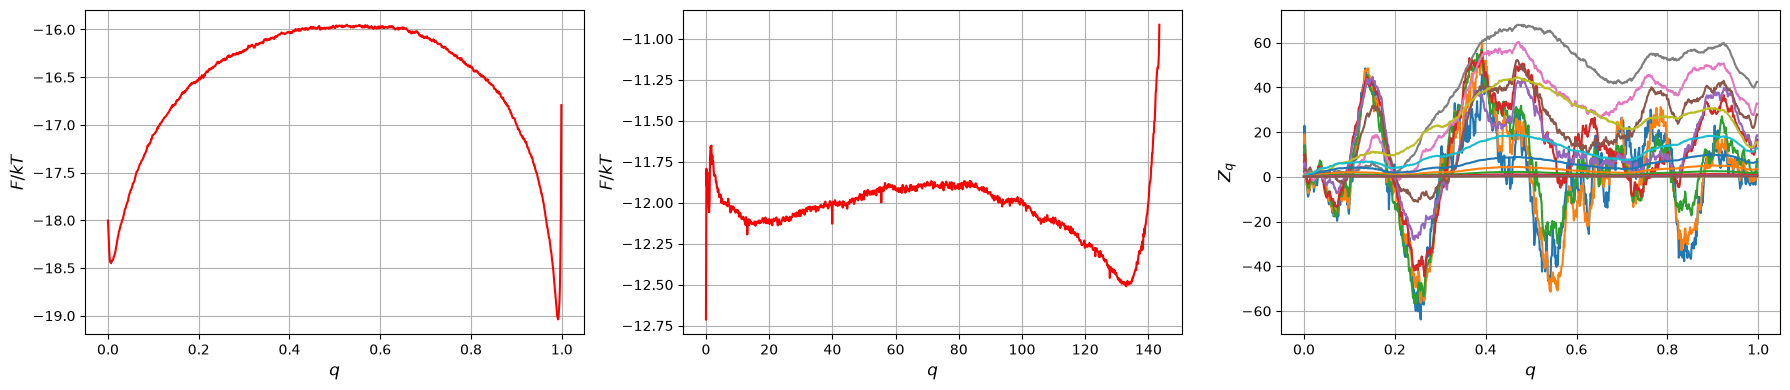

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


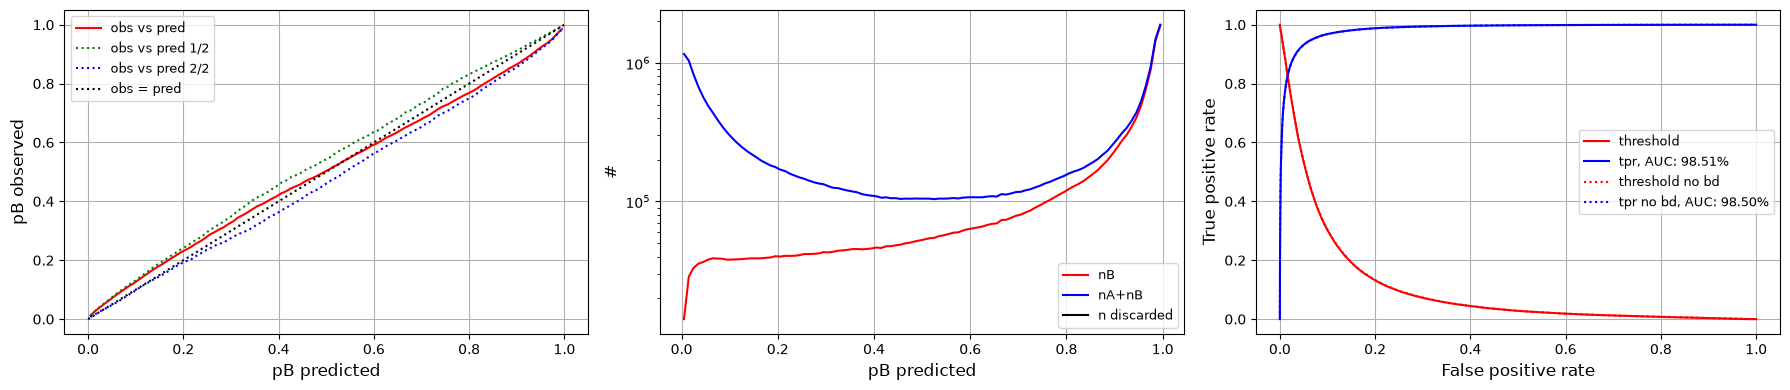

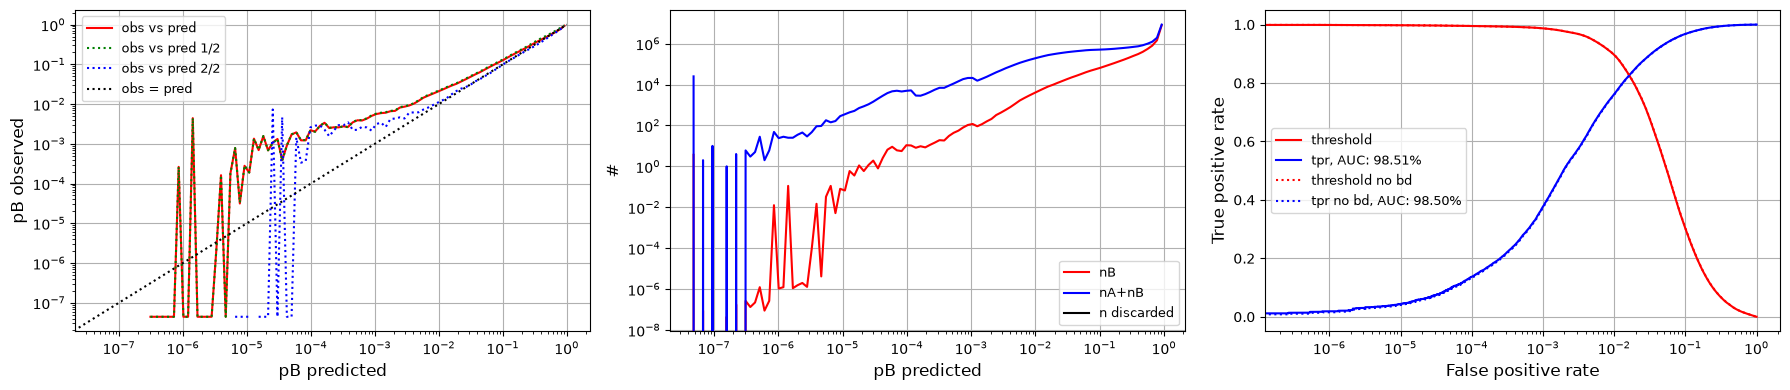

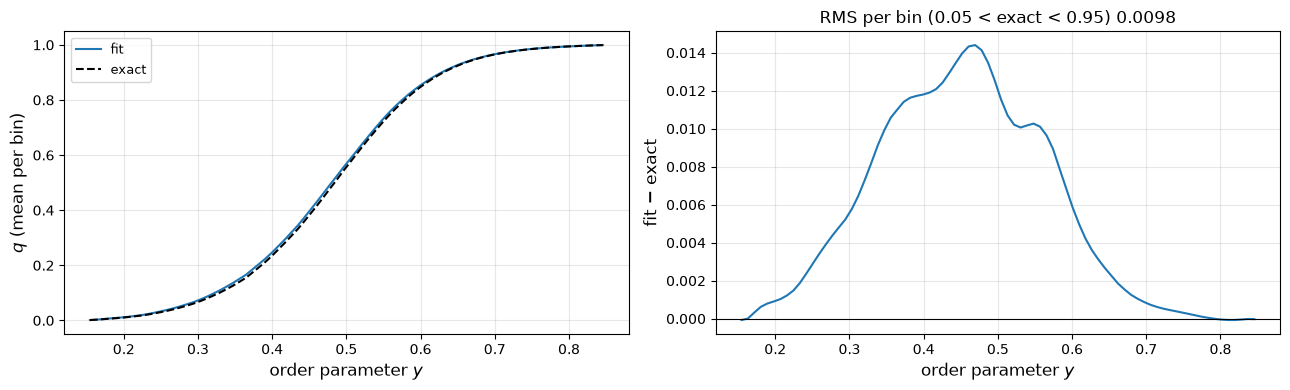

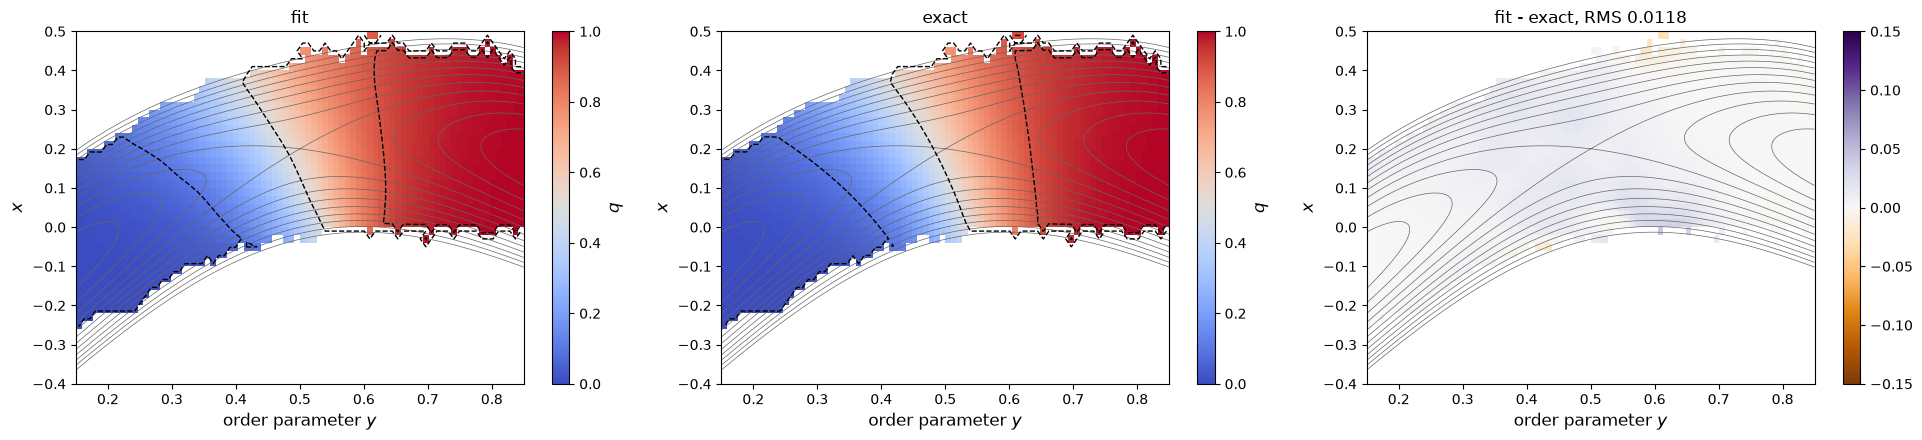

1000 iterations (warm-up, envelope 1) | RMS(fit - exact) 0.0099
#=1500, dr2=3896.12, zqs_z=1.85219, sdzqs=22.239, |dx|=0.00122359, time=43.193
#=2000, dr2=3895.98, zqs_z=1.8577, sdzqs=22.1242, |dx|=0.000163838, time=85.9
#=2500, dr2=3895.97, zqs_z=1.8696, sdzqs=22.2277, |dx|=0.000105863, time=128.607
#=3000, dr2=3895.91, zqs_z=1.83268, sdzqs=22.136, |dx|=8.62762e-05, time=171.294
#=3500, dr2=3895.99, zqs_z=1.85498, sdzqs=22.1206, |dx|=6.14263e-05, time=214.639


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)
/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/2d_curved_channel/brownian_g10/staple/infretis_copy/cc_br/rejections/seed1/it3500 ---


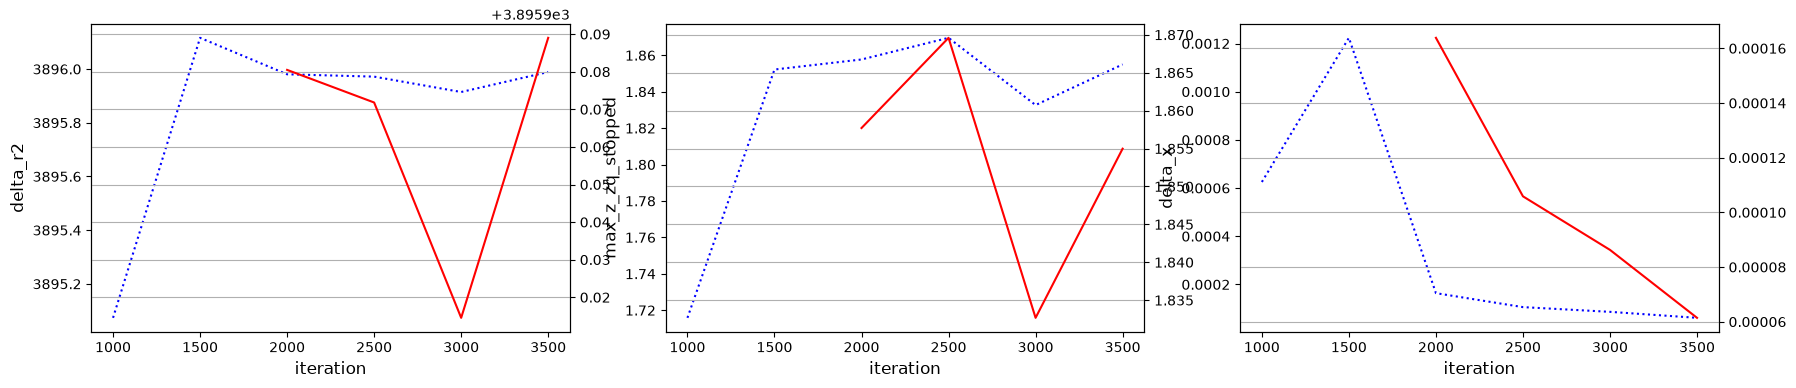

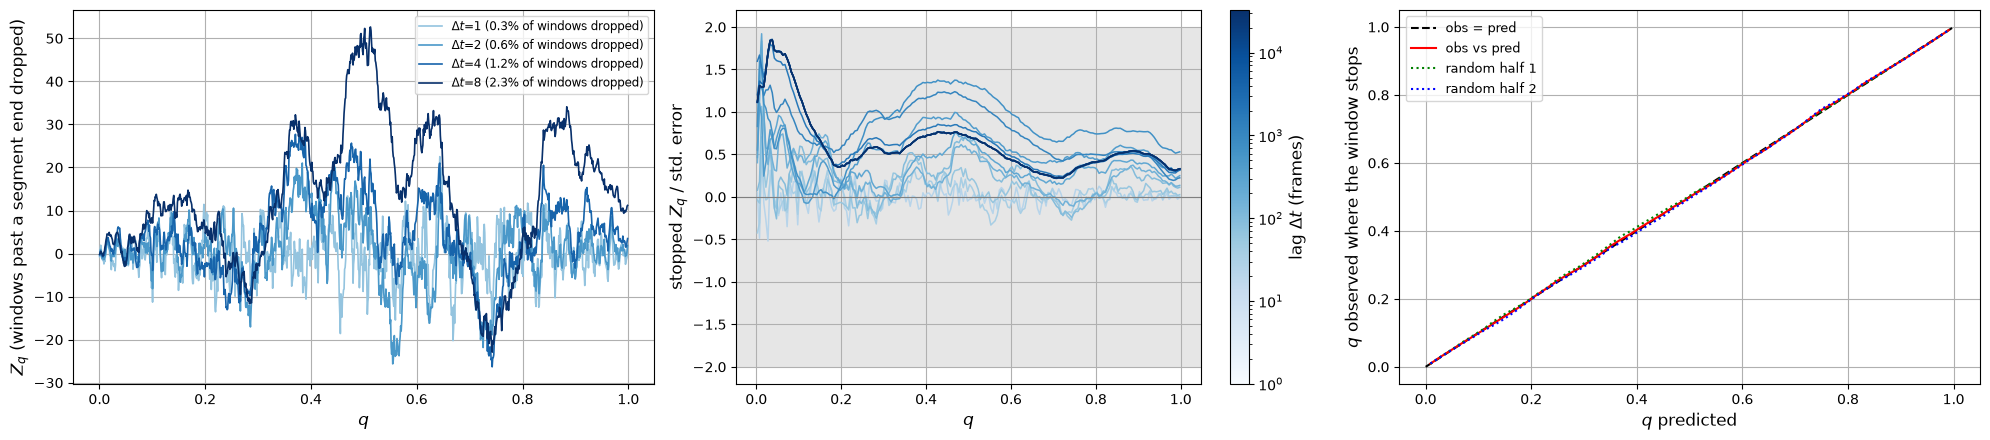

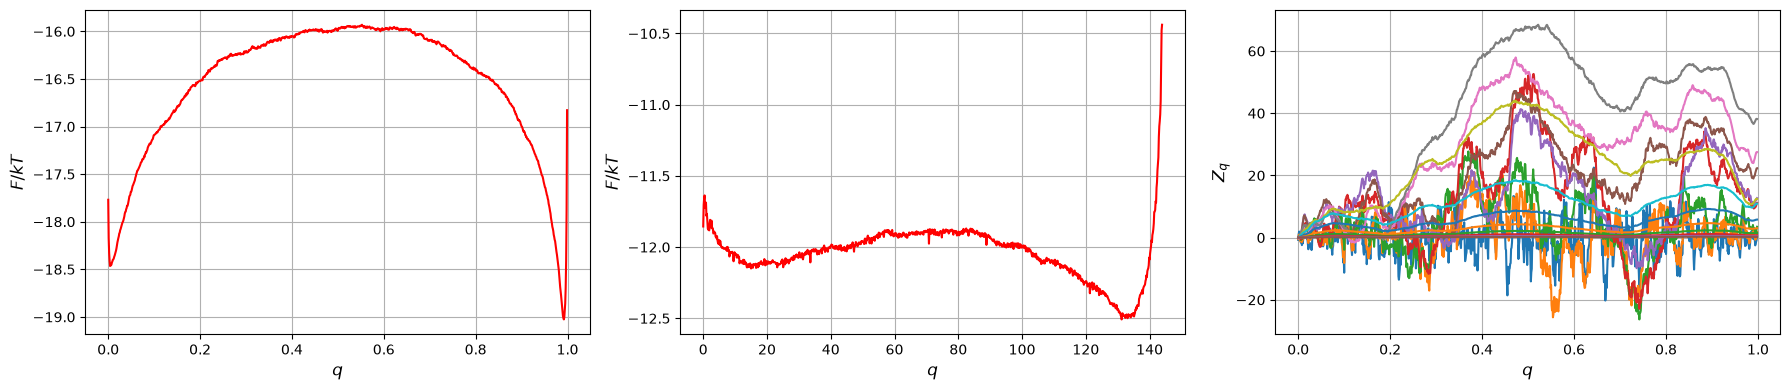

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


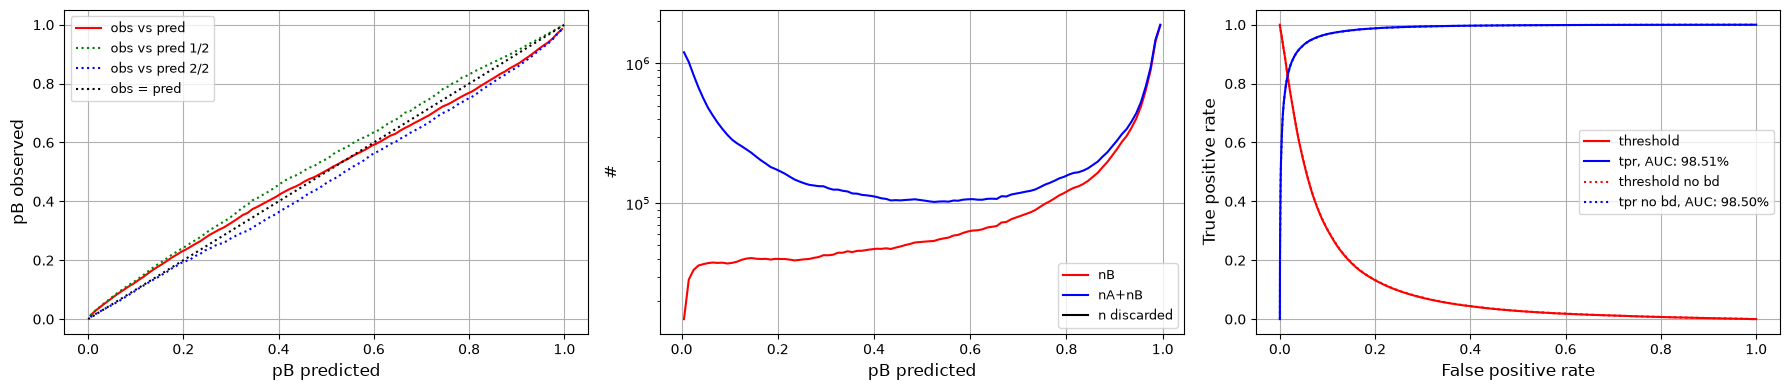

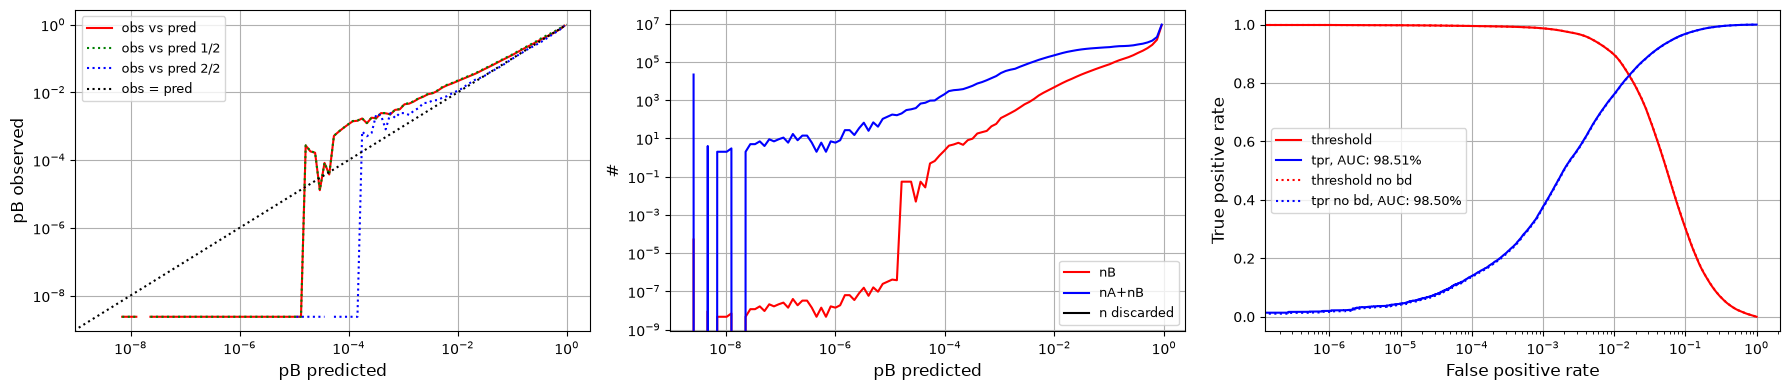

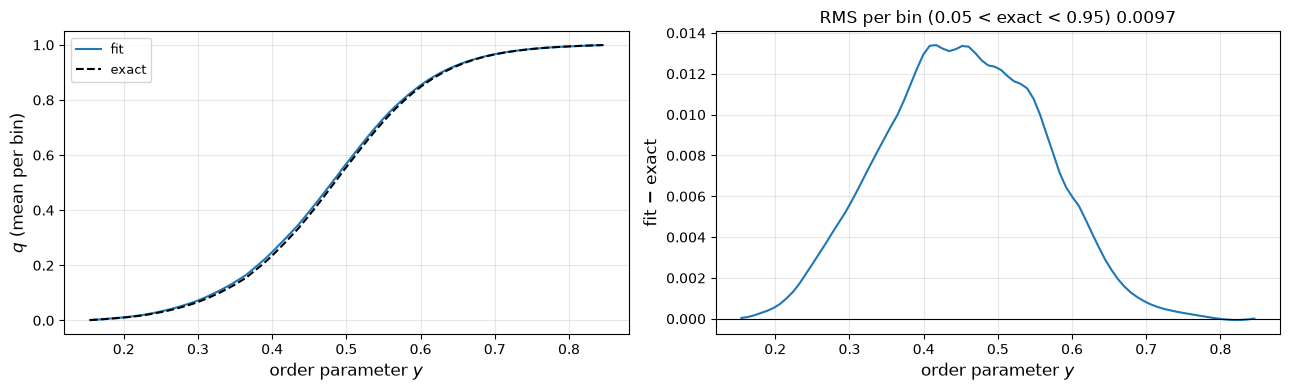

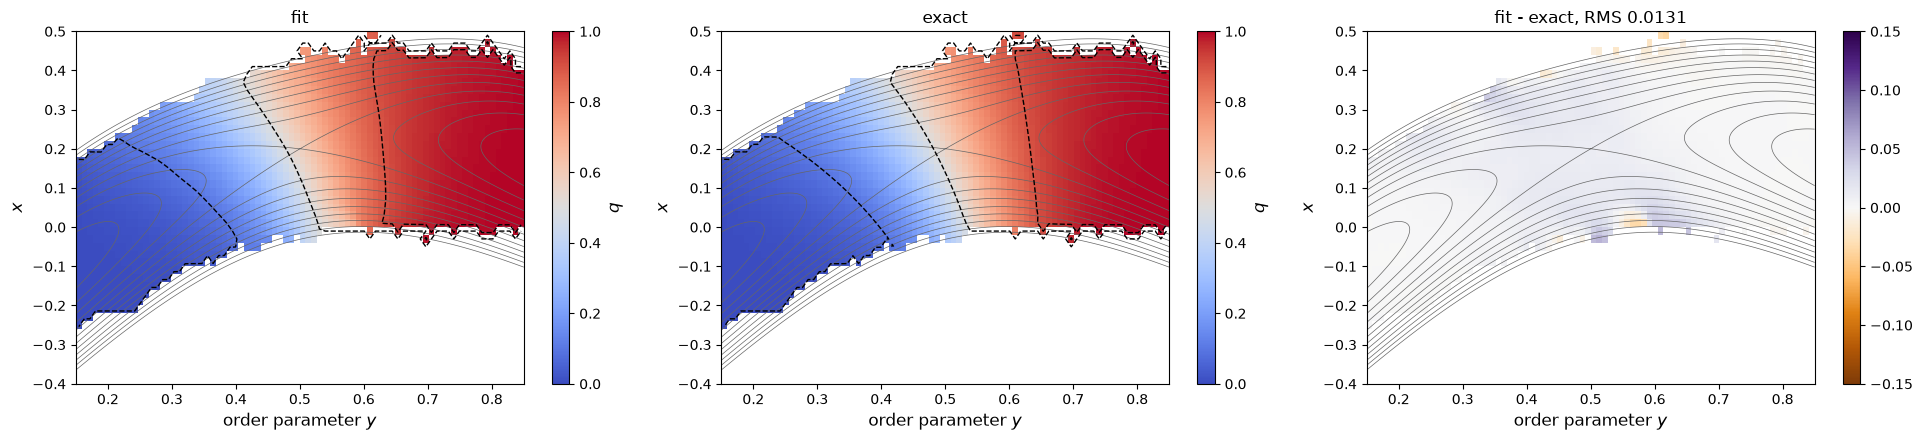

3500 iterations (main, envelope 0.01) | RMS(fit - exact) 0.0099
#=4000, dr2=3895.82, zqs_z=1.84139, sdzqs=22.1195, |dx|=5.33318e-05, time=42.6643
#=4500, dr2=3895.93, zqs_z=1.84869, sdzqs=22.2375, |dx|=5.15439e-05, time=85.6178
#=5000, dr2=3895.84, zqs_z=1.84556, sdzqs=22.1192, |dx|=6.64247e-05, time=128.327
#=5500, dr2=3896.01, zqs_z=1.84421, sdzqs=22.2247, |dx|=5.37354e-05, time=171.491

Training interrupted at iteration 5991; keeping the RC of the last completed update.


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)
/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/2d_curved_channel/brownian_g10/staple/infretis_copy/cc_br/rejections/seed1/it6000 ---


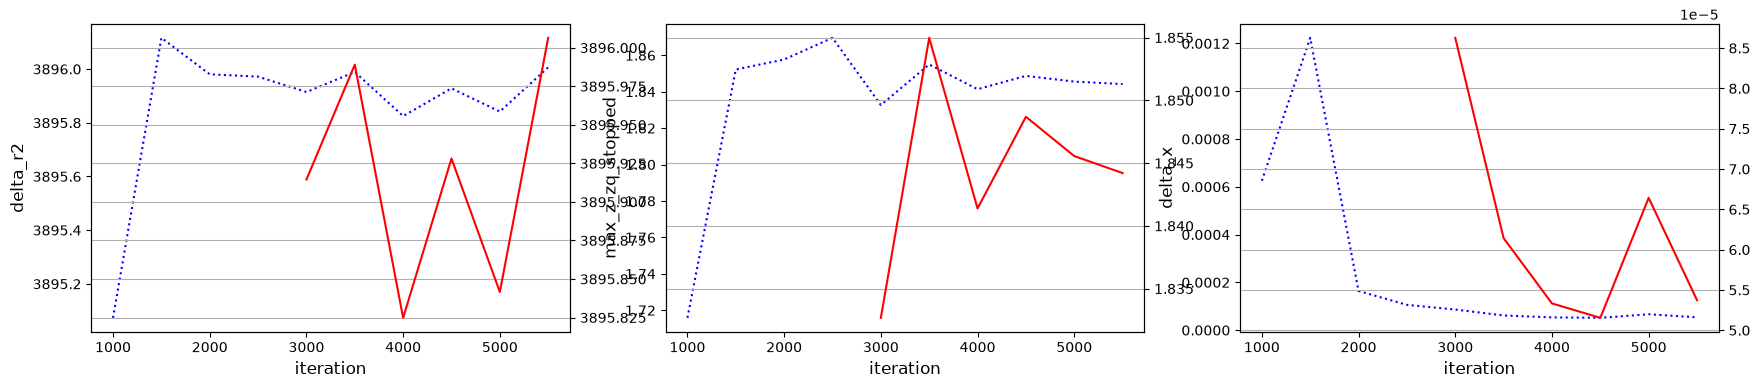

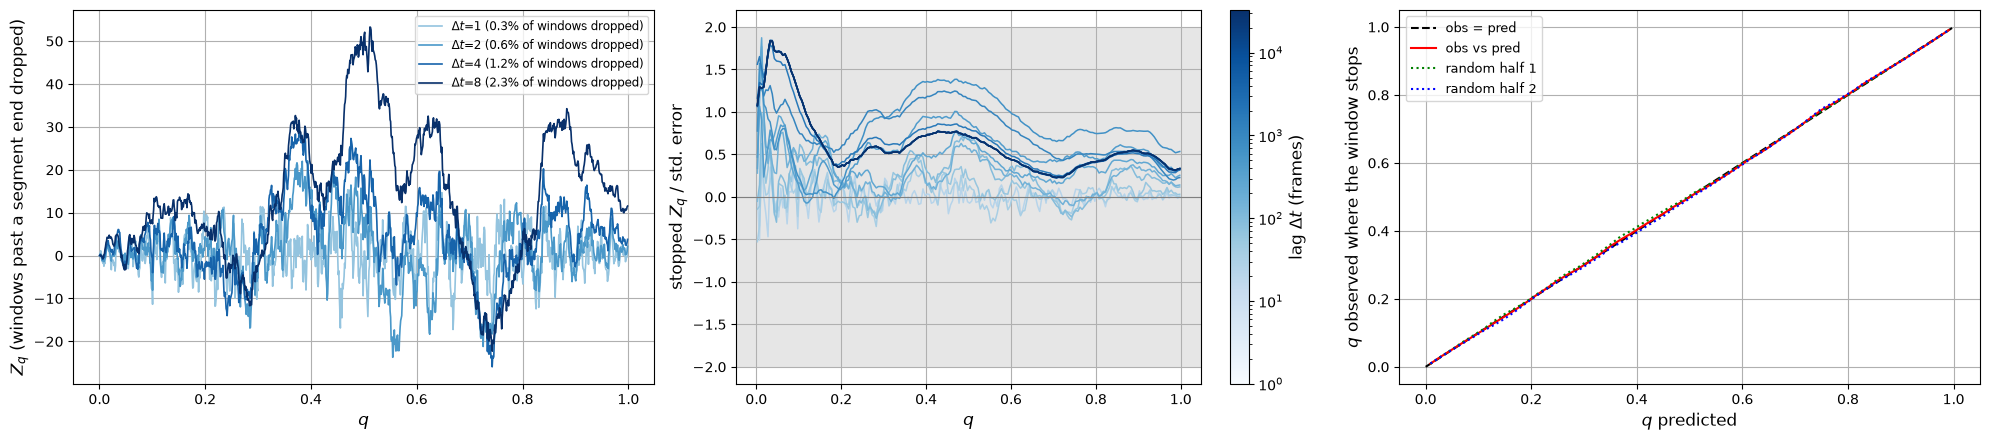

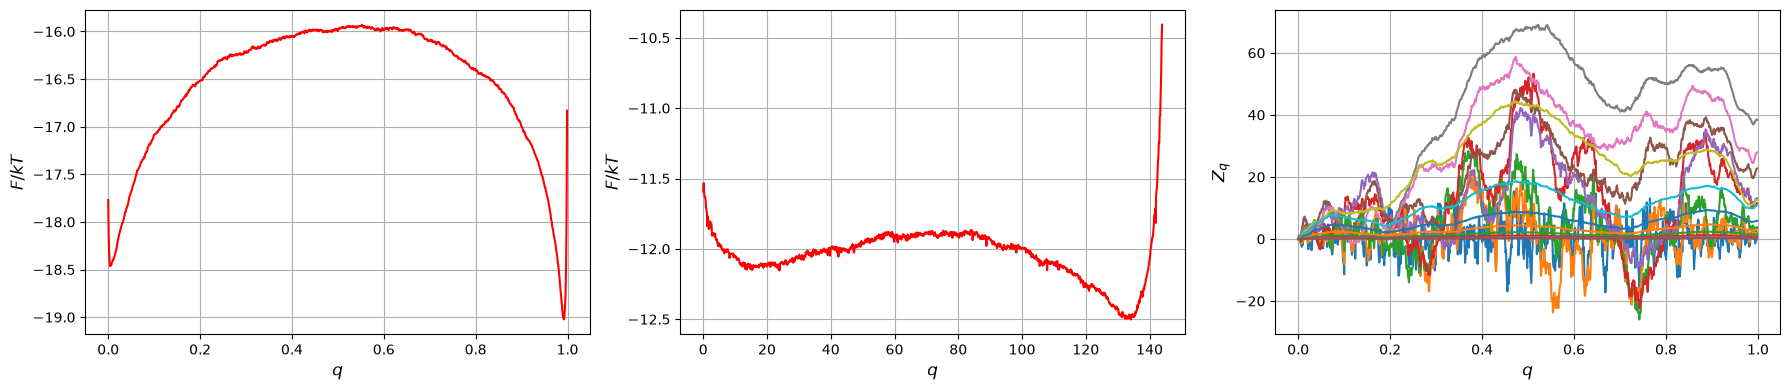

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


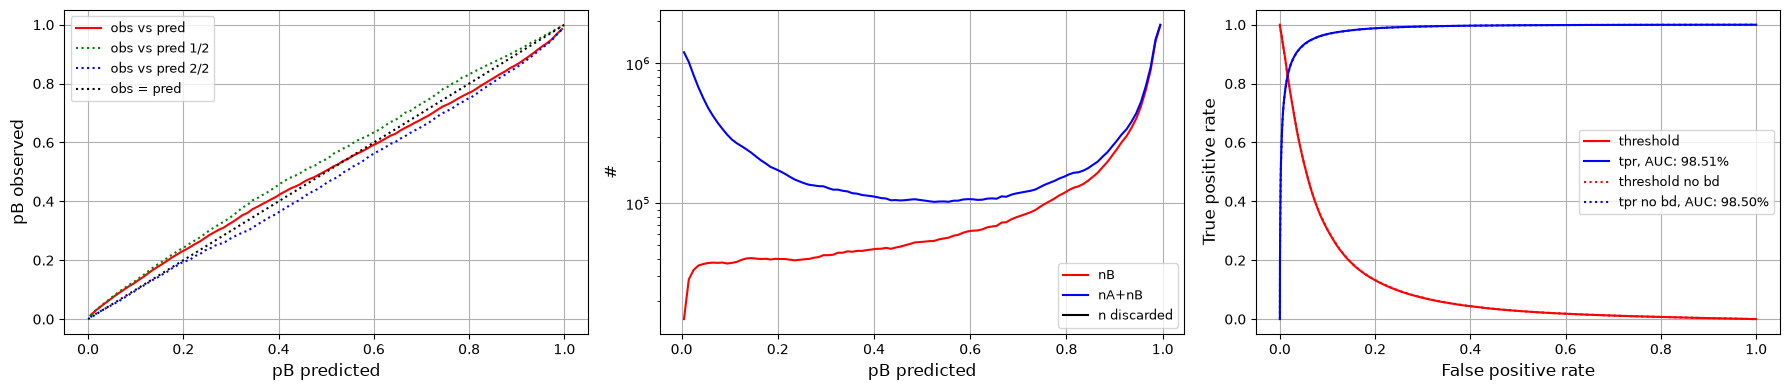

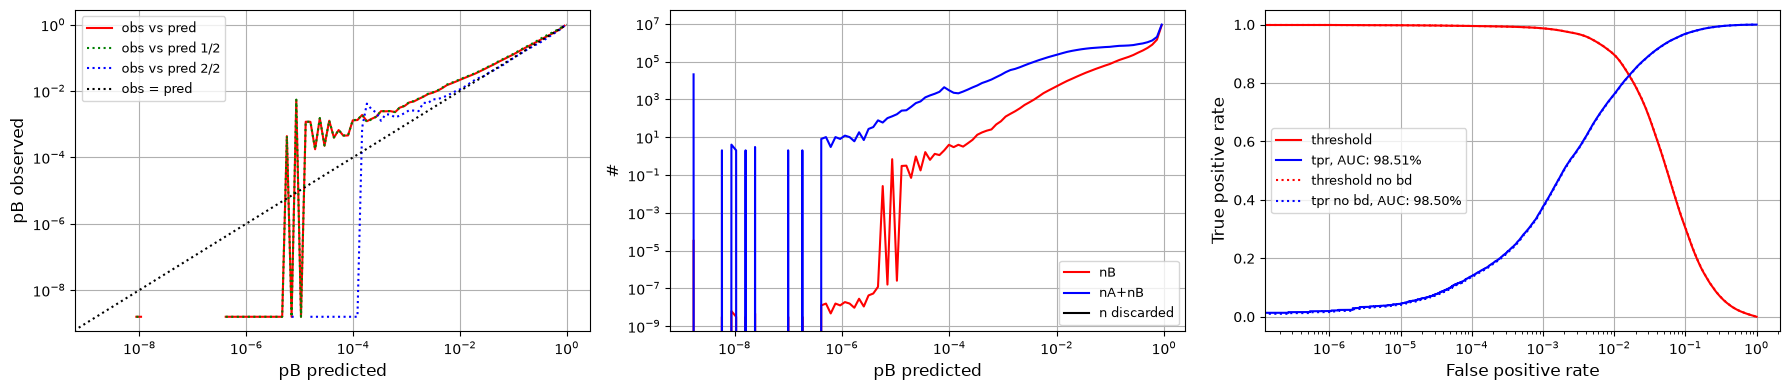

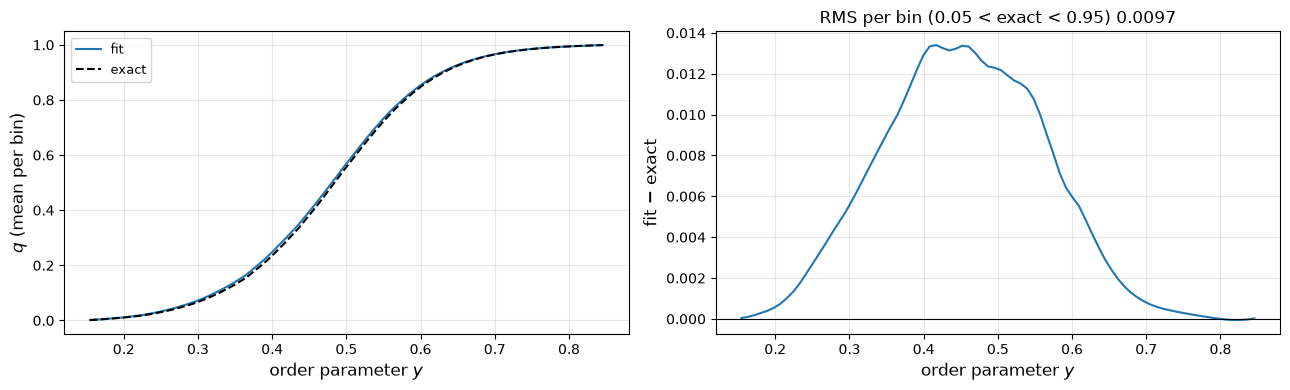

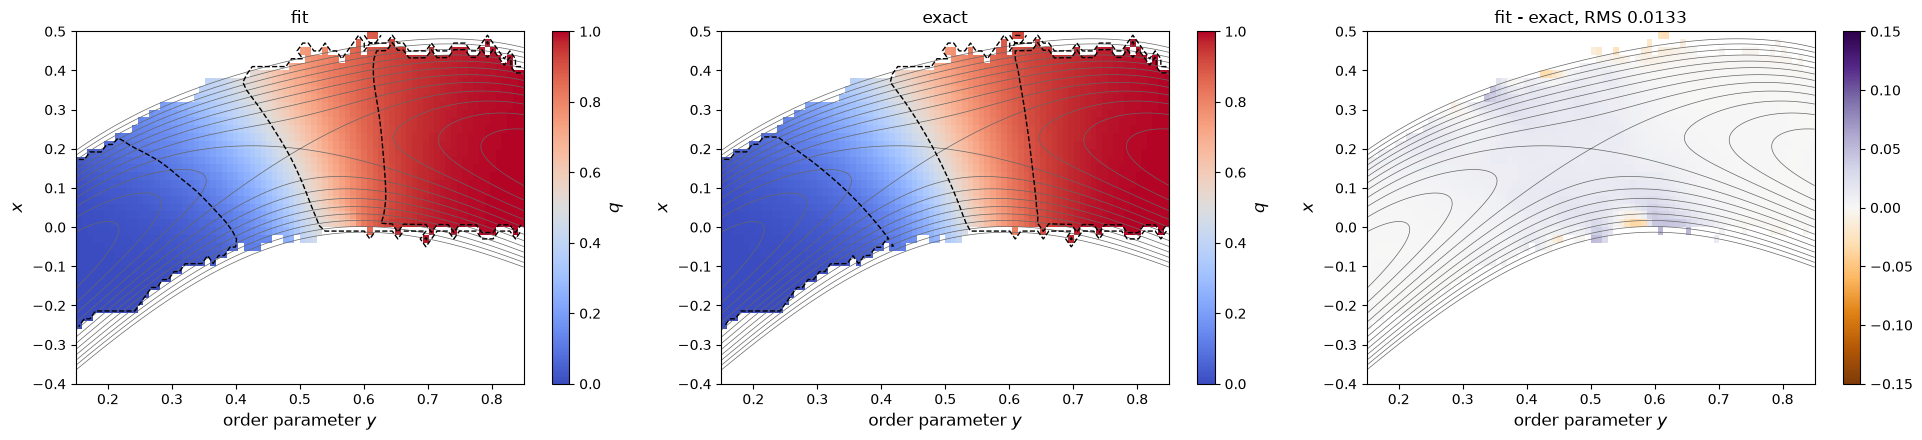

6000 iterations (main, envelope 0.01) | RMS(fit - exact) 0.0099
#=6000, dr2=3895.88, zqs_z=1.83888, sdzqs=22.2717, |dx|=1.7084e-05, time=12.3455

Training interrupted at iteration 6500; keeping the RC of the last completed update.


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)
/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/2d_curved_channel/brownian_g10/staple/infretis_copy/cc_br/rejections/seed1/it8500 ---


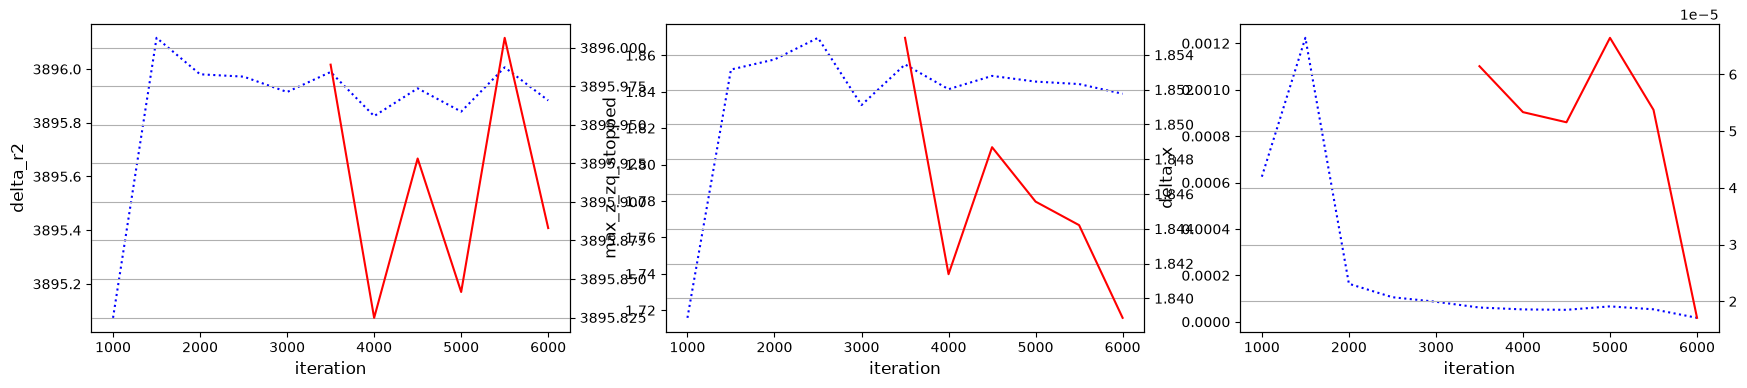

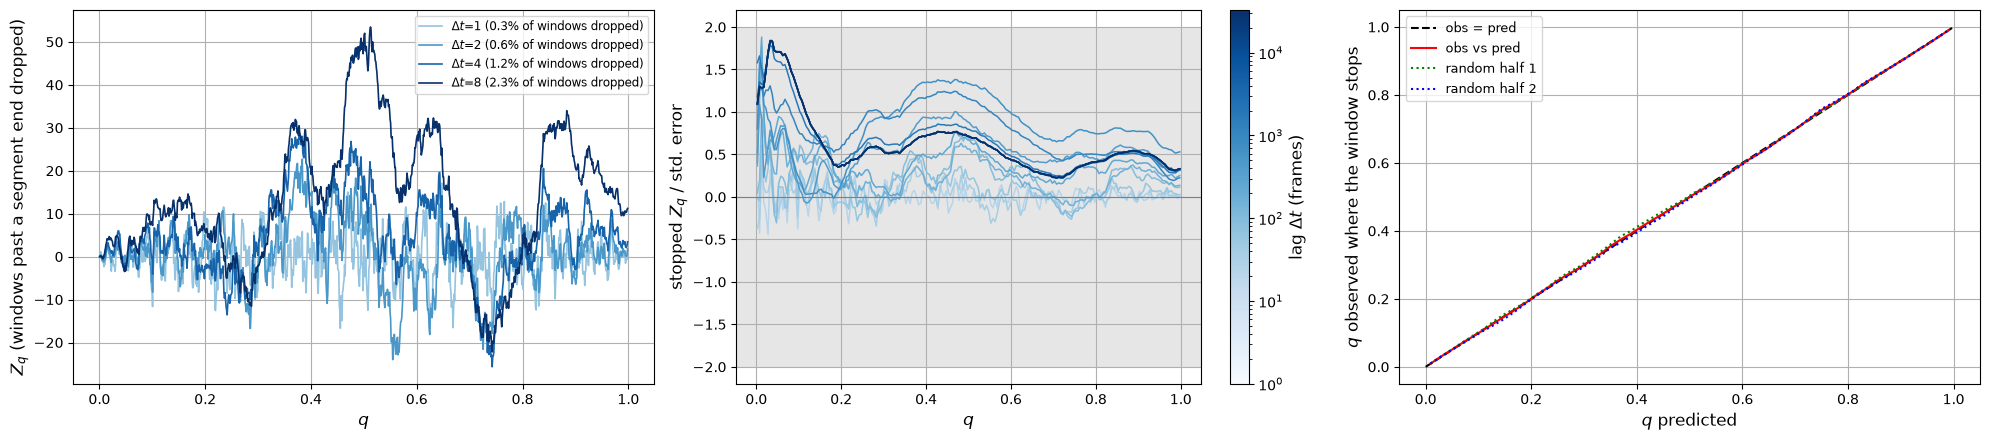

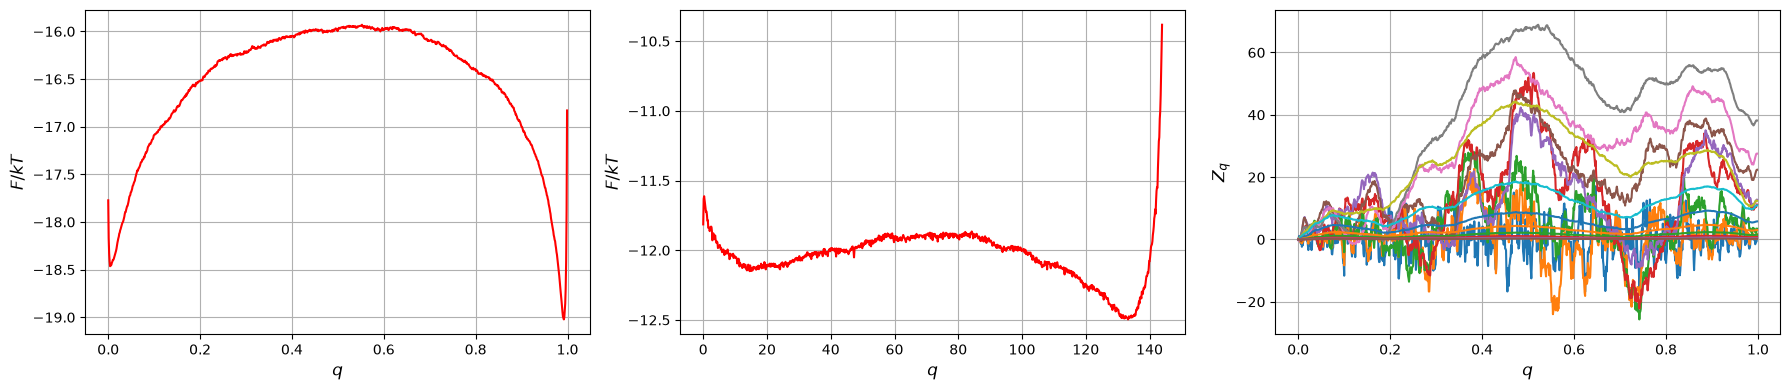

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


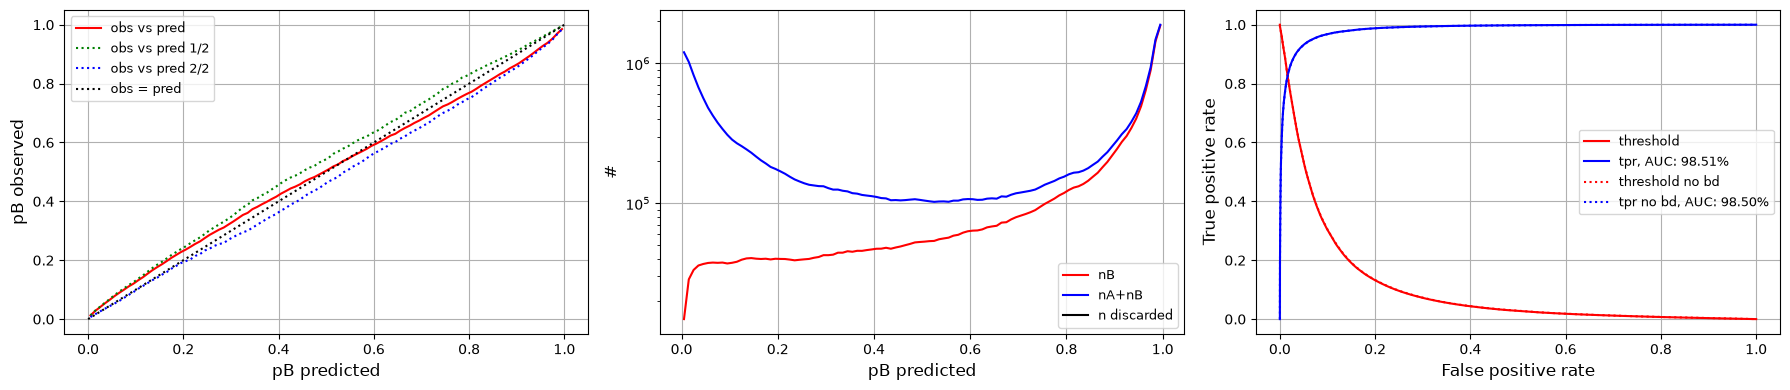

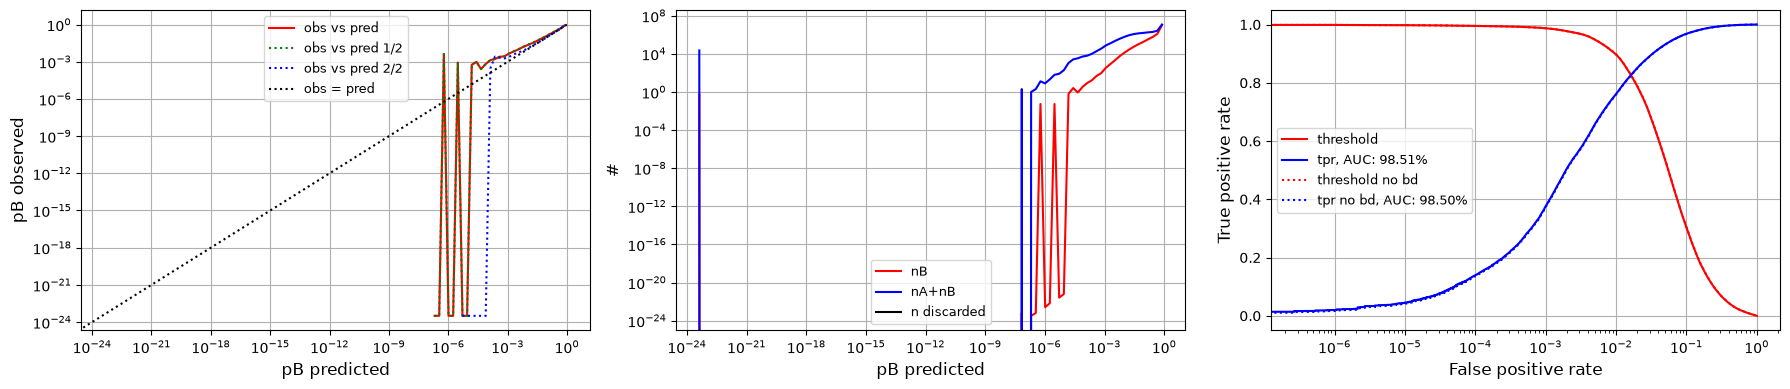

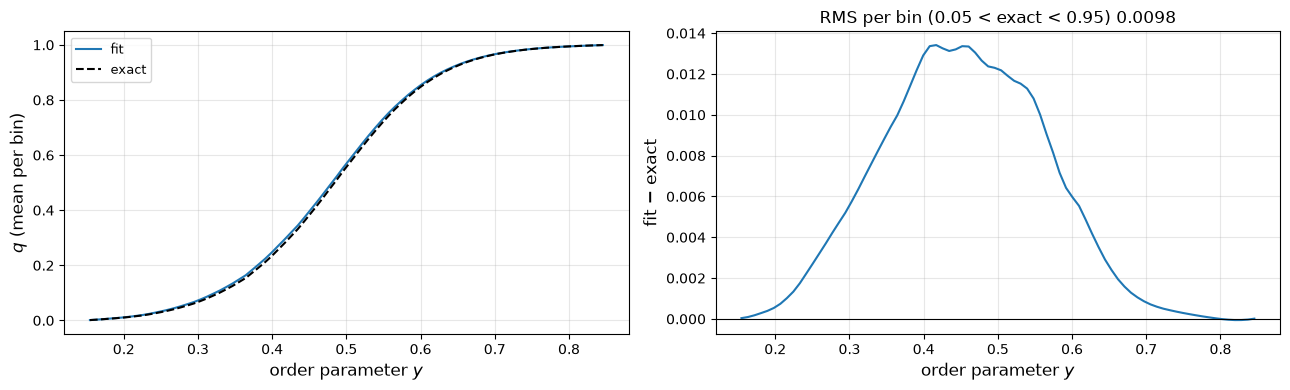

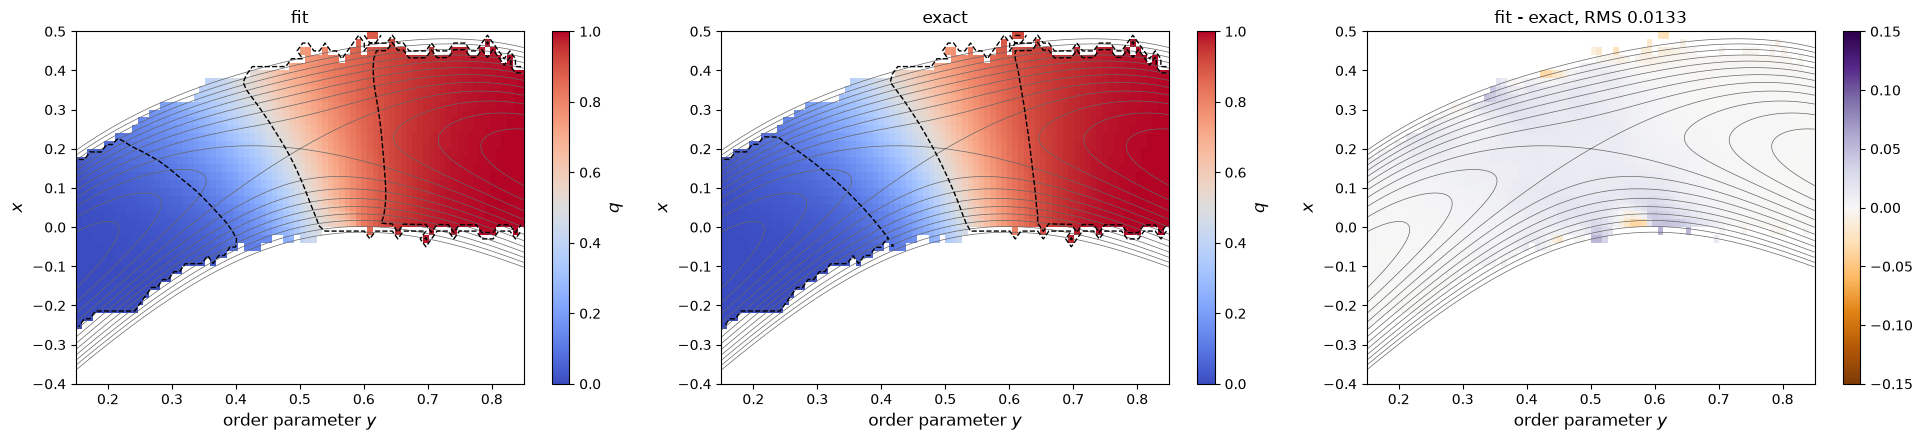

8500 iterations (main, envelope 0.01) | RMS(fit - exact) 0.0099
#=7000, dr2=3895.97, zqs_z=1.8507, sdzqs=22.1563, |dx|=3.84814e-05, time=42.6977

Training interrupted at iteration 7500; keeping the RC of the last completed update.


/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)
/local/data/data-fbsskr/Students/elias/optimalrcs/optimalrcs-cupy/optimalrcs.py:397: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.tight_layout()
/local/data/data-fbsskr/Students/elias/optimalrcs/examples/seed_runs.py:44: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.gcf().savefig(f'{folder}/{tag}_{name}.png', dpi=100)


--- /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/2d_curved_channel/brownian_g10/staple/infretis_copy/cc_br/rejections/seed1/it11000 ---


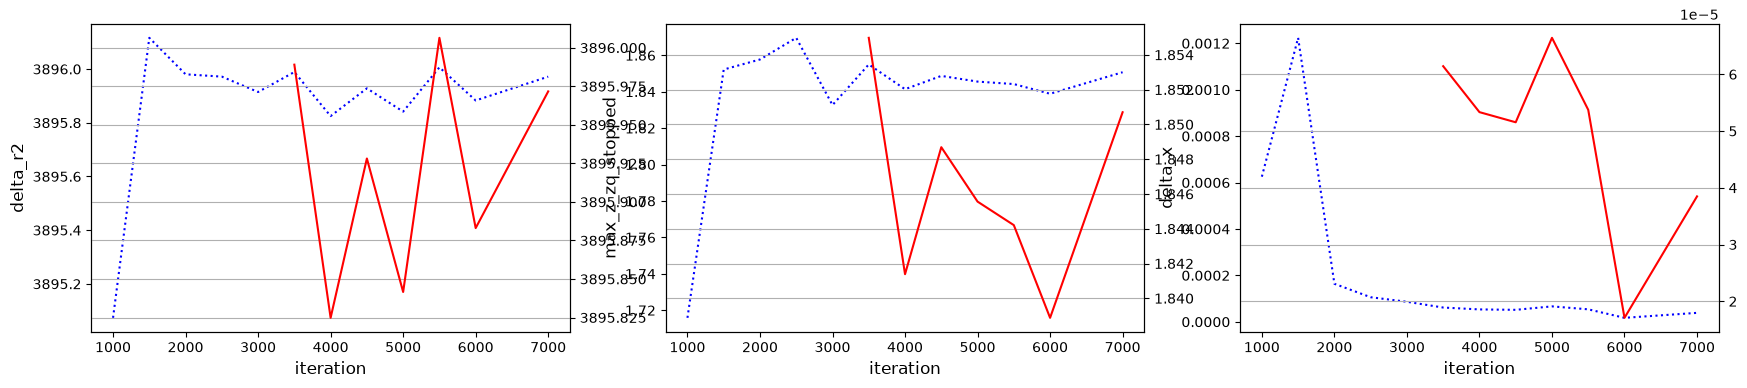

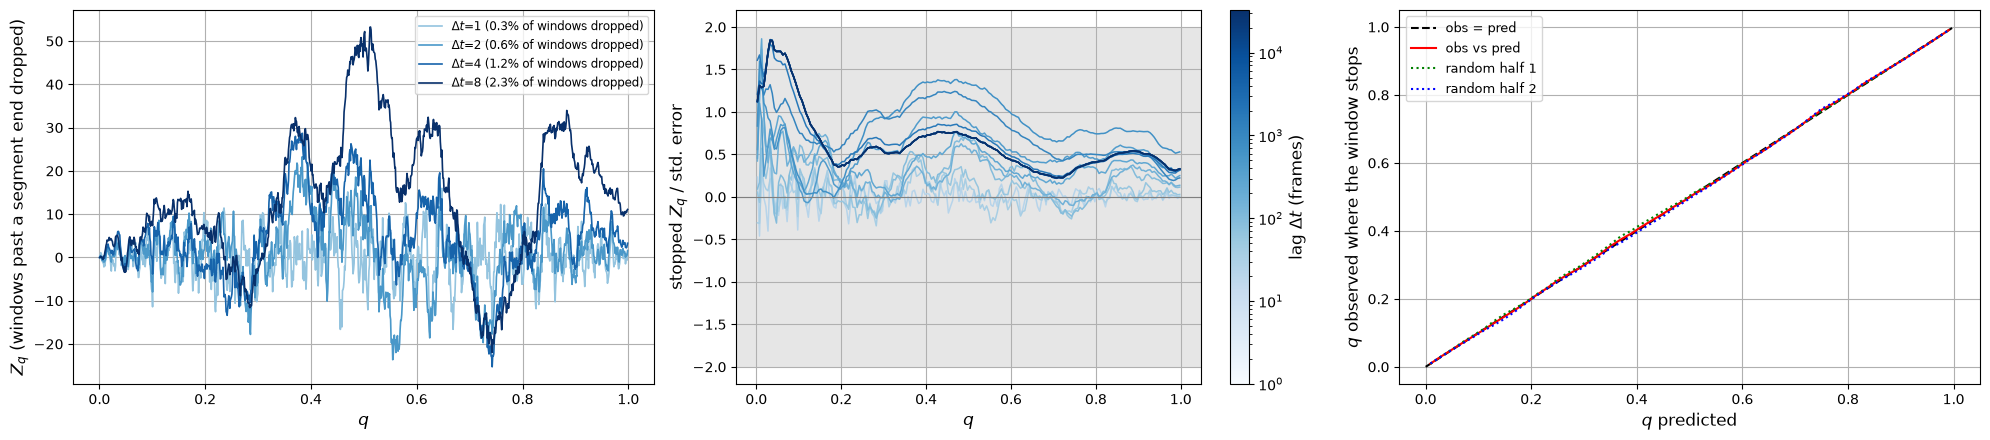

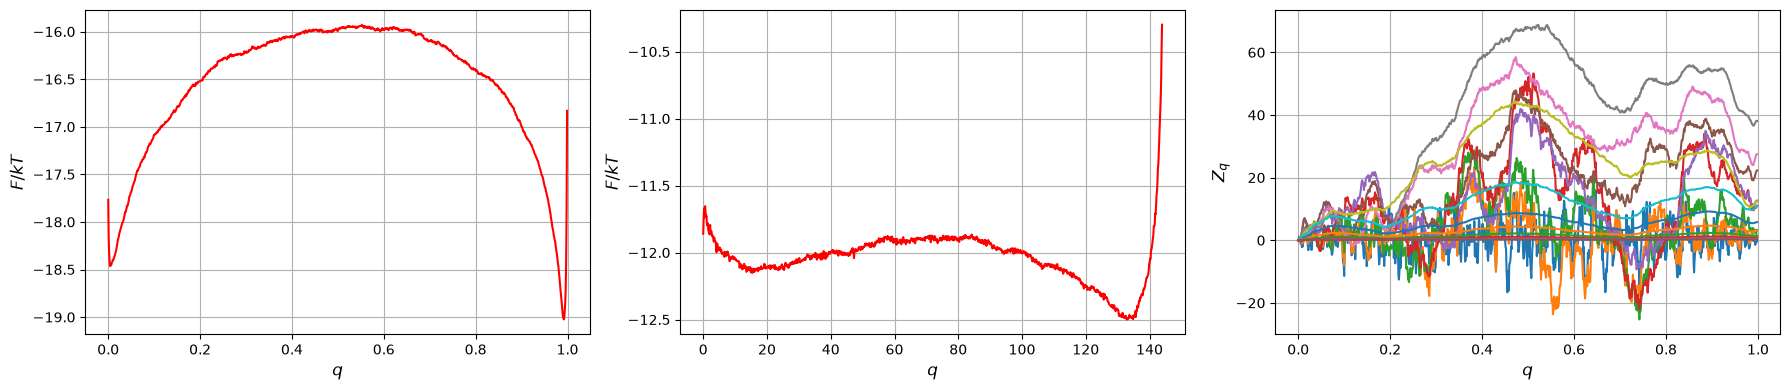

/local/data/data-fbsskr/Students/elias/rctis/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


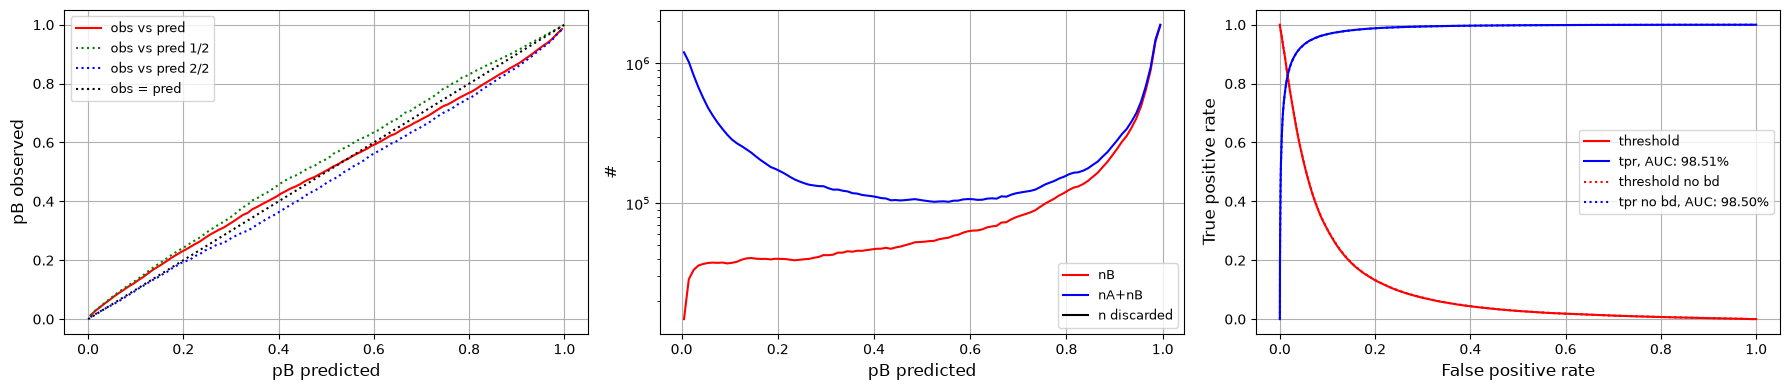

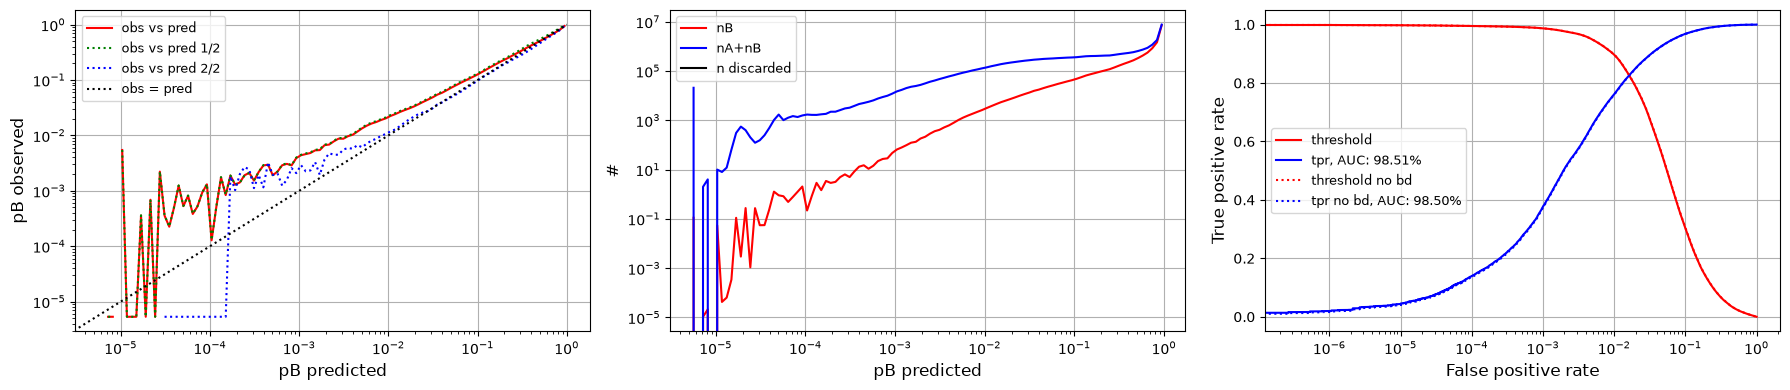

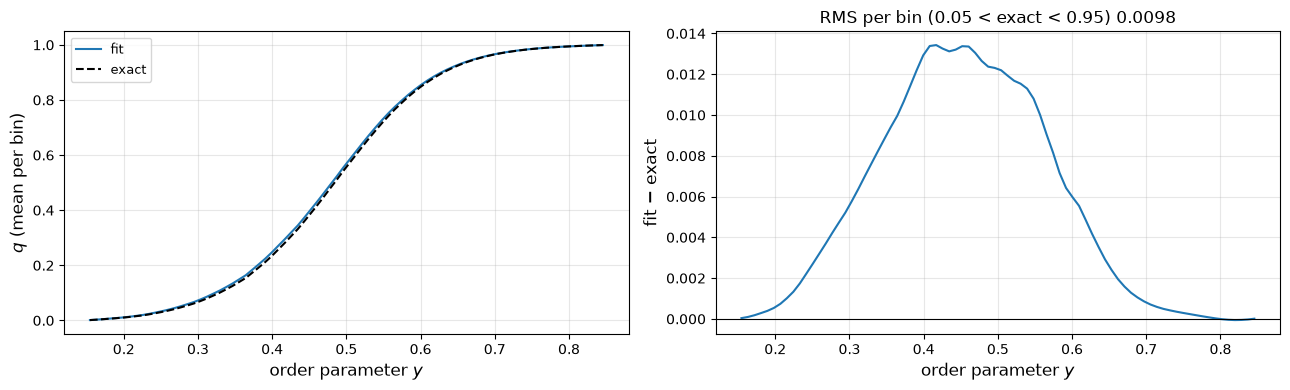

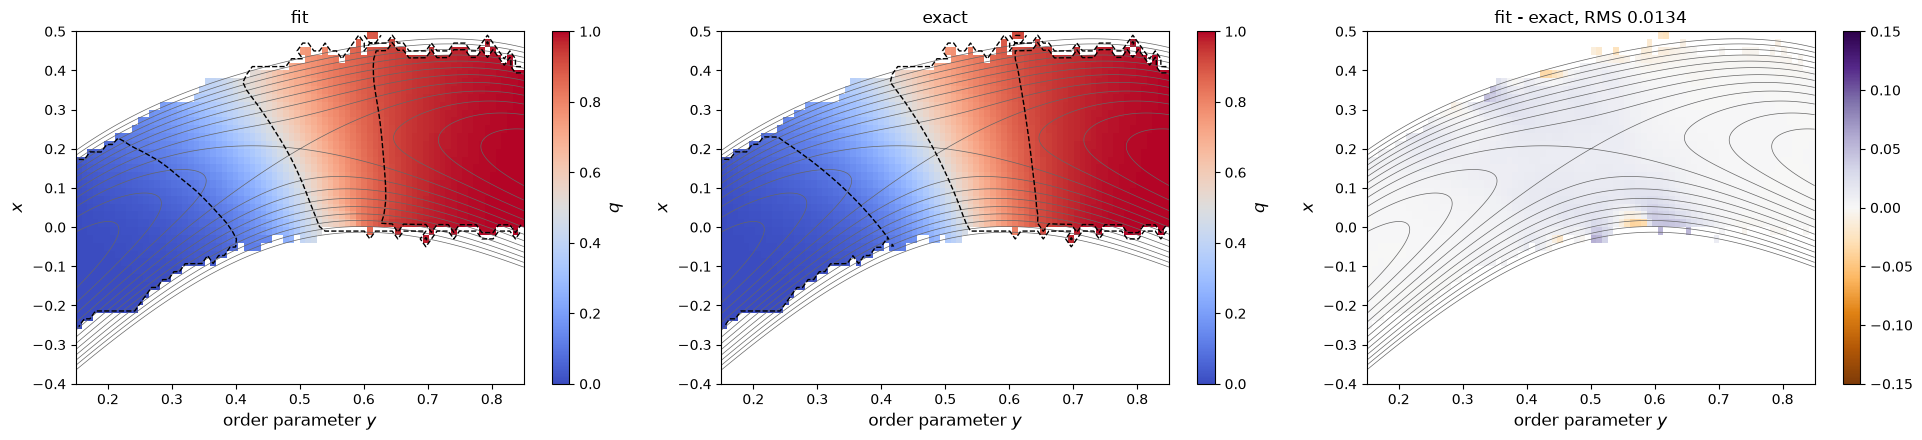

11000 iterations (main, envelope 0.01) | RMS(fit - exact) 0.0099


In [8]:
fit_kw = dict(ny=NY, print_step=PRINT_STEP, lazy_basis=LAZY_BASIS, save_min_metric='max_z_zq_stopped',
              metrics_print=('iter', 'delta_r2', 'max_z_zq_stopped', 'max_sd_zq_stopped', 'delta_x', 'time_elapsed'))
fits = {}                                      # weighting -> final q per seed, exact committor, fit time, zqs_z history
for name, d in datas.items():                  # one fit per weighting: the same frames, other path weights
    qe = q_exact_of(d.X_all) if q_exact_of is not None else None
    X_cv = cp.asarray(d.X)                     # the CVs on the GPU, once
    extras, report = extras_for(d, qe), report_for(d, qe)

    def comp_y():
        """The CV of an iteration: one of the fit CVs, drawn at random."""
        return X_cv[:, np.random.randint(X_cv.shape[1])]

    t0 = time.time()
    results = {}
    for seed in SEEDS:
        print(f'===== fit, weighting {name}, seed {seed} =====', flush=True)
        np.random.seed(seed)                   # which CV and envelope centre each iteration draws
        cp.random.seed(seed)
        folder = f'{OUT}/{name}/seed{seed}'

        # the committor of the path pieces
        q = optimalrcs.CommittorNE(
            boundary0=d.boundary0,             # state A: q = 0
            boundary1=d.boundary1,             # state B: q = 1
            i_traj=d.i_traj,                   # piece of every frame
            t_traj=d.t_traj,                   # time of every frame within its path
            path_weights=d.path_weights,       # weight of the frame's path (mean 1)
            group_traj=d.group_traj,           # path of every frame: its pieces are one unit in the error estimates
        )
        q.set_fixed_traj_length_trap(b_all, TRAP_LEN if STOPPED_ENDS else 2 ** 16)   # A/B ends: no window is dropped
        if STOPPED_ENDS:
            q.set_stopped_traj_end(stop_end)   # turn ends: a window passing the end uses q there

        # warm-up with a wide envelope
        n_done = 0
        if WARMUP_ITER:
            optimalrcs.envelope_scale = WARMUP_ENVELOPE
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=WARMUP_ITER, **fit_kw)
            n_done += WARMUP_ITER
            show_stage(q, folder, n_done, f'warm-up, envelope {WARMUP_ENVELOPE}', extras, report)

        # main fit, in chunks of CHUNK iterations (fit_transform continues from the current q)
        optimalrcs.envelope_scale = ENVELOPE
        while n_done < WARMUP_ITER + MAX_ITER:
            n_iter = min(CHUNK, WARMUP_ITER + MAX_ITER - n_done)
            q.fit_transform(comp_y, gamma=GAMMA, max_iter=n_iter, **fit_kw)
            n_done += n_iter
            show_stage(q, folder, n_done, f'main, envelope {ENVELOPE}', extras, report)

        results[seed] = cp.asnumpy(q.r_traj)
        np.save(f'{folder}/q_traj.npy', results[seed].astype(np.float32))
        zqs_z = np.array([float(v) for v in q.metrics_history['max_z_zq_stopped']])   # (of the last seed, as before)
        del q                                  # free the GPU for the next fit
        cp.get_default_memory_pool().free_all_blocks()
    fits[name] = dict(r=results, q_exact=qe, t_fit=time.time() - t0, zqs_z=zqs_z)
    del X_cv

## 7. Results

**Table:** per weighting and seed, the data size, the final and lowest `zqs_z` of the run (its own data; about 2 or less is consistent), and with the exact committor the path-weighted RMS of fit − exact over the frames with 0.05 < q_exact < 0.95 and over the bins in that range.

**Committor along λ:** the path-weighted mean q per λ bin of every fit, the exact committor averaged the same way (dashed), and fit − exact. For 2D data the mean over x can hide errors of opposite sign; the maps below show them.

**Maps:** fit − exact per (y, x) bin for every fit, with the exact committor in the first panel (dashed: q = 0.1, 0.5, 0.9; grey: the potential).

,,paths,pieces,frames,zqs_z_final,zqs_z_min,fit_minutes,rms_frames,rms_bins_lambda
weighting,seed,,,,,,,,
rejections,1,29360,99072,24916795,1.8507,1.7158,16.0463,0.0099,0.0098


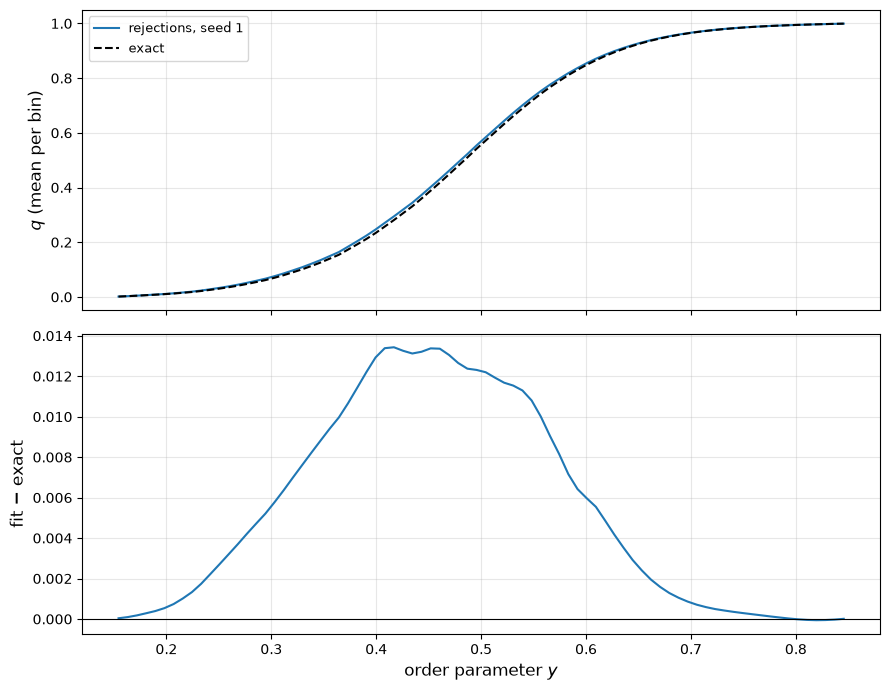

In [9]:
rows, profiles = [], {}
for name, fit in fits.items():
    d = datas[name]
    fr = ~(d.boundary0 | d.boundary1)
    edges = edges_for(d)
    bm = seed_runs.BinnedMean((d.lam,), edges[:1], fr)
    w_mean = bm(d.path_weights)
    qe = fit['q_exact']
    for s, r in fit['r'].items():
        row = dict(weighting=name, seed=s, paths=len(np.unique(d.group_traj)), pieces=int(d.i_traj.max() + 1),
                   frames=len(r), zqs_z_final=fit['zqs_z'][-1], zqs_z_min=fit['zqs_z'][1:].min(),
                   fit_minutes=fit['t_fit'] / 60 / len(fit['r']))
        profiles[(name, s)] = bm(d.path_weights * r) / w_mean
        if qe is not None:
            t = fr & (qe > 0.05) & (qe < 0.95)
            row['rms_frames'] = np.sqrt(np.sum(d.path_weights[t] * (r[t] - qe[t]) ** 2) / np.sum(d.path_weights[t]))
            pe = bm(d.path_weights * qe) / w_mean
            tb = (pe > 0.05) & (pe < 0.95)
            row['rms_bins_lambda'] = np.sqrt(np.nanmean((profiles[(name, s)] - pe)[tb] ** 2))
            profiles[('exact', name)] = pe
        rows.append(row)
summary = pd.DataFrame(rows).set_index(['weighting', 'seed'])
os.makedirs(OUT, exist_ok=True)
summary.to_csv(f'{OUT}/summary.csv')
display(summary.round(4))

edges = edges_for(data)
mid = (edges[0][1:] + edges[0][:-1]) / 2
has_exact = any(k[0] == 'exact' for k in profiles)
fig, axes = plt.subplots(2 if has_exact else 1, 1, figsize=(9, 7 if has_exact else 4), sharex=True, squeeze=False)
for (name, s), P in profiles.items():
    if name == 'exact':
        continue
    axes[0, 0].plot(mid, P, label=f'{name}, seed {s}')
    if has_exact:
        axes[1, 0].plot(mid, P - profiles[('exact', name)], label=f'{name}, seed {s}')
if has_exact:
    axes[0, 0].plot(mid, profiles[('exact', next(iter(fits)))], 'k--', label='exact')
    axes[1, 0].axhline(0, color='k', lw=0.8)
    axes[1, 0].set(ylabel='fit $-$ exact')
    axes[1, 0].grid(alpha=0.3)
axes[0, 0].set(ylabel='$q$ (mean per bin)')
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.3)
axes[-1, 0].set(xlabel=XLABEL)
fig.tight_layout()
fig.savefig(f'{OUT}/profiles.png', dpi=110)
plt.show()

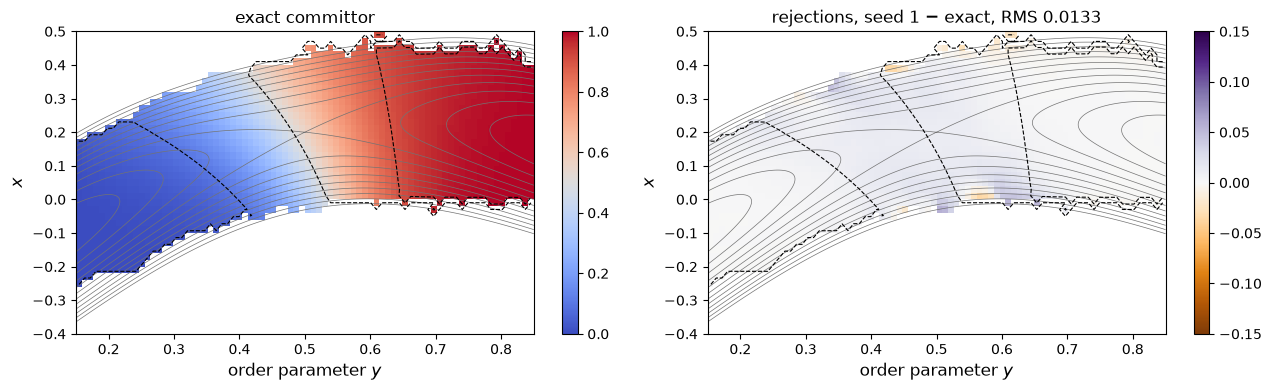

In [10]:
DIFF_LIM = 0.15                    # colour range of the difference maps
e1, e2 = edges_for(data)
m1, m2 = (e1[1:] + e1[:-1]) / 2, (e2[1:] + e2[:-1]) / 2
first = next(iter(fits))
bm2 = seed_runs.BinnedMean((data.X_all[:, 0], data.X_all[:, 1]), (e1, e2), ~(data.boundary0 | data.boundary1))
w2 = bm2(data.path_weights)
qe0 = fits[first]['q_exact']
ref_map = None if qe0 is None else bm2(data.path_weights * qe0) / w2
panels = [] if ref_map is None else [(ref_map, 'exact committor', 'coolwarm', (0, 1))]
for name, fit in fits.items():
    d = datas[name]
    bmd = seed_runs.BinnedMean((d.X_all[:, 0], d.X_all[:, 1]), (e1, e2), ~(d.boundary0 | d.boundary1))
    wd = bmd(d.path_weights)
    for s, r in fit['r'].items():
        M = bmd(d.path_weights * r) / wd
        if ref_map is None:
            panels.append((M, f'{name}, seed {s}', 'coolwarm', (0, 1)))
        else:
            D = M - ref_map
            t = (ref_map > 0.05) & (ref_map < 0.95)
            panels.append((D, f'{name}, seed {s} $-$ exact, RMS {np.sqrt(np.nanmean(D[t] ** 2)):.4f}',
                           'PuOr', (-DIFF_LIM, DIFF_LIM)))
n_cols = min(3, len(panels))
n_rows = -(-len(panels) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6.5 * n_cols, 4 * n_rows), squeeze=False)
for ax, (M, title, cmap, (lo, hi)) in zip(axes.ravel(), panels):
    im = ax.pcolormesh(e1, e2, M.T, cmap=cmap, vmin=lo, vmax=hi)
    if CONTOURS is not None:
        g1, g2, V, lev = CONTOURS
        ax.contour(g1, g2, V.T, levels=lev, colors='0.45', linewidths=0.5)
    if ref_map is not None:
        ax.contour(m1, m2, np.nan_to_num(ref_map, nan=0.5).T, levels=[0.1, 0.5, 0.9], colors='k',
                   linewidths=0.8, linestyles='--')
    ax.set(title=title, xlabel=LABELS[0], ylabel=LABELS[1], xlim=(e1[0], e1[-1]), ylim=(e2[0], e2[-1]))
    fig.colorbar(im, ax=ax)
for ax in axes.ravel()[len(panels):]:
    ax.axis('off')
fig.tight_layout()
fig.savefig(f'{OUT}/maps.png', dpi=110)
plt.show()

## 8. Save

Every fit's q per frame with its frames, in the format of `load_tis_data_cupy.py`'s `committor.npz` (`r`, `lam`, `X_all`, `i_traj`, `t_traj`, `group_traj`, `path_weights`, `boundary0`, `boundary1`), as `<OUT>/<weighting>/seed<s>/committor.npz`. (`run_seeds` also saved each final q alone as `q_traj.npy`.)

In [11]:
for name, fit in fits.items():
    d = datas[name]
    for s, r in fit['r'].items():
        path = f'{OUT}/{name}/seed{s}/committor.npz'
        np.savez(path, r=r, lam=d.lam, X_all=d.X_all, i_traj=d.i_traj, t_traj=d.t_traj, group_traj=d.group_traj,
                 path_weights=d.path_weights, boundary0=d.boundary0, boundary1=d.boundary1,
                 weighting=name, tis_dir=TIS_DIR)
        print('saved', path)

saved /local/data/data-fbsskr/Students/elias/optimalrcs/examples/figures_by_potential/2d_curved_channel/brownian_g10/staple/infretis_copy/cc_br/rejections/seed1/committor.npz
